# Projeto de Classificação de Imagens Oftalmológicas com Deep Learning

**Cenário Clínico Selecionado:** Use Case 3 - Sistema de Referenciação Hospitalar.
O objetivo deste sistema é atuar como um filtro no fluxo de triagem, reduzindo o número de exames enviados para avaliação especializada. Apenas os casos com elevada probabilidade de patologia (Catarata ou Retinopatia Diabética) devem ser encaminhados, otimizando os recursos do hospital.

1. **Introdução** (Contextualização Clínica)
2. **Dataset** (Setup, Carregamento & Análise Exploratória - EDA)
3. **Metodologia**
   * 3.1 Pré-processamento e Divisão dos Dados
   * 3.2 CNN Baseline
   * 3.3 CNN Regularizada
   * 3.4 Transfer Learning
     * 3.4.1 EfficientNetB0
     * 3.4.2 ResNet50
4. **Resultados**
   * 4.1 Definição de Funções de Avaliação
   * 4.2 Loss Function vs Accuracy
   * 4.3 Matriz de Confusão e Classification Report
   * 4.4 Curvas ROC e Precision-Recall
   * 4.5 Sensibilidade vs Especificidade por Threshold
   * 4.6 Tabela Comparativa de Modelos
5. **Explicabilidade Visual (Grad-CAM)**
6. **Modelo Multimodal**

# 1. Introdução
---

**Contextualização do Caso Clínico: Use Case 3 - Sistema de Referenciação Hospitalar**
O objetivo principal deste projeto é desenvolver e avaliar um sistema de apoio à decisão clínica baseado em Deep Learning para a classificação de imagens oftalmológicas (Catarata, Retinopatia Diabética e Normal).

No âmbito do **Use Case 3**, o sistema atua como um filtro crítico no fluxo de triagem hospitalar. O foco principal não é apenas maximizar a exatidão global (*accuracy*), mas sim reduzir o volume de exames enviados desnecessariamente para avaliação especializada, garantindo em simultâneo uma sensibilidade (*recall*) extremamente elevada nas classes patológicas para evitar a ocorrência de Falsos Negativos (doentes com patologia que não são referenciados).

## 2 — Dataset (Setup, Carregamento & Análise Exploratória - EDA)
---

Nesta secção, configuramos o ambiente de desenvolvimento, definimos a reproducibilidade do sistema e analisamos as características estruturais e estatísticas do dataset fornecido.

In [1]:
# célula de importações
# Bibliotecas que vamos usar

#!pip install tensorflow
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import random
import os
import re
import hashlib
from pathlib import Path
from itertools import product
from collections import defaultdict, Counter
from PIL import Image, ImageOps
import nltk
from nltk.corpus import stopwords
from transformers import AutoTokenizer, AutoModel
import torch
from sklearn.model_selection import train_test_split, StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay, f1_score, recall_score, roc_auc_score)
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score

import tensorflow as tf

from sklearn.preprocessing import label_binarize
from tensorflow.keras import models, layers, optimizers, callbacks, regularizers, Model
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.models import Sequential
from tensorflow.keras.regularizers import l2
from tensorflow.keras.layers import Input, Dense, Dropout, Flatten, Conv2D, MaxPooling2D
from tensorflow.keras.applications import EfficientNetB0, ResNet50
from keras.utils import to_categorical

In [2]:
# Célula de configuração de ambiente
# Set random seeds for reproducibility

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)
os.environ["TF_DETERMINISTIC_OPS"] = "1"

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
tf.keras.utils.set_random_seed(SEED)



In [3]:

#função para carregar as imagens de uma pasta e atribuir-lhes um rótulo
def load_images_from_folder(folder, label):
    images = []
    labels = []
    nomes = []
    # sorted(): os.listdir order is filesystem-dependent and would silently
    # break alignment between X_original and groups if images are re-uploaded.
    for filename in sorted(os.listdir(folder)):
        img_path = os.path.join(folder, filename)
        img = Image.open(img_path).convert("RGB")

        # Padding para quadrado sem distorção antes do resize
        img = ImageOps.pad(img, (224, 224), color=(0, 0, 0))

        images.append(np.array(img))
        labels.append(label)
        nomes.append(filename)
    return images, labels, nomes


In [4]:
# Detecta se está no Colab. 'COLAB_GPU' tracks the GPU runtime, not Colab
# itself: on a CPU runtime it is absent, drive.mount is skipped, the local
# branch is taken and loading dies on FileNotFoundError.
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    base_dir = '/content/drive/MyDrive'
else:
    # os.getcwd() is wherever the kernel was launched, NOT the notebook's
    # directory. Resolve the repo root explicitly and anchor data to it.
    REPO_ROOT = Path.cwd().resolve()
    while not (REPO_ROOT / '.git').exists() and REPO_ROOT != REPO_ROOT.parent:
        REPO_ROOT = REPO_ROOT.parent
    base_dir = str(REPO_ROOT)

cataract_folder = os.path.join(base_dir,"ocular", "cataract")
diabetic_folder = os.path.join(base_dir, "ocular", "diabetic_retinopathy")
normal_folder = os.path.join(base_dir, "ocular", "normal")

print(cataract_folder)
print(diabetic_folder)
print(normal_folder)

# Carregar as imagens das pastas e criar as targets
cataract_images, cataract_labels, cataract_files = load_images_from_folder(cataract_folder, 0)
diabetic_images, diabetic_labels, diabetic_files = load_images_from_folder(diabetic_folder, 1)
normal_images, normal_labels, normal_files = load_images_from_folder(normal_folder, 2)


# Concatenar os dados
X_original = np.array(cataract_images + diabetic_images + normal_images)
y = np.array(cataract_labels + diabetic_labels + normal_labels)
# Same concatenation order as X_original/y -- this is what makes the
# groups alignment structural instead of a re-listing coincidence.
nomes_ficheiros = np.array(cataract_files + diabetic_files + normal_files)
labels_ficheiros = np.array([0] * len(cataract_files)
                            + [1] * len(diabetic_files)
                            + [2] * len(normal_files))

# Verificar o formato dos dados
print(f"Formato dos dados: {X_original.shape}")
print(f"Formato das labels: {y.shape}")

Mounted at /content/drive
/content/drive/MyDrive/ocular/cataract
/content/drive/MyDrive/ocular/diabetic_retinopathy
/content/drive/MyDrive/ocular/normal
Formato dos dados: (2570, 224, 224, 3)
Formato das labels: (2570,)


In [5]:
# Mapa de pastas -> nome legível (alinhado com os teus labels 0/1/2)
FOLDERS = {
    0: ("cataract", cataract_folder),
    1: ("diabetic_retinopathy", diabetic_folder),
    2: ("normal", normal_folder),
}

print("="*60)
print("INVENTÁRIO E INTEGRIDADE")
print("="*60)

records = []          # (classe, ficheiro, ok, largura, altura, modo, hash)
corrupt = []
for lab, (name, folder) in FOLDERS.items():
    for fn in sorted(os.listdir(folder)):
        path = os.path.join(folder, fn)
        try:
            with Image.open(path) as im:     # deteta corrupção
                im.verify()
            with Image.open(path) as im:     # reabrir: verify() invalida o objeto
                w, h = im.size
                mode = im.mode
            with open(path, "rb") as f:
                h_md5 = hashlib.md5(f.read()).hexdigest()
            records.append((lab, name, fn, w, h, mode, h_md5))
        except Exception as e:
            corrupt.append((name, fn, str(e)))

print(f"Total de ficheiros válidos: {len(records)}")
print(f"Ficheiros corrompidos / não abrem: {len(corrupt)}")
for c in corrupt[:10]:
    print("   ", c)

# --- Dimensões originais  ---
print("\n" + "="*60)
print("DIMENSÕES ORIGINAIS")
print("="*60)
dims = Counter((r[3], r[4]) for r in records)
print("Tamanhos mais comuns (largura, altura):")
for (w, h), n in dims.most_common(8):
    print(f"   {w}x{h}: {n} imagens")
modes = Counter(r[5] for r in records)
print("Modos de cor:", dict(modes))

# --- Duplicados por conteúdo (hash) ---
print("\n" + "="*60)
print("DUPLICADOS")
print("="*60)
by_hash = defaultdict(list)
for r in records:
    by_hash[r[6]].append((r[1], r[2]))   # (classe, ficheiro)
dups = {h: v for h, v in by_hash.items() if len(v) > 1}
print(f"Grupos de imagens idênticas: {len(dups)}")
total_dup_imgs = sum(len(v) for v in dups.values())
print(f"Total de imagens envolvidas: {total_dup_imgs}")

cross_class = 0
for h, v in dups.items():
    classes = set(c for c, _ in v)
    if len(classes) > 1:
        cross_class += 1
print(f"Grupos que CRUZAM classes diferentes: {cross_class}")
if cross_class > 0:
    print("  -> mesma imagem com labels diferentes: erro de dataset")



INVENTÁRIO E INTEGRIDADE
Total de ficheiros válidos: 2570
Ficheiros corrompidos / não abrem: 0

DIMENSÕES ORIGINAIS
Tamanhos mais comuns (largura, altura):
   512x512: 2470 imagens
   2592x1728: 76 imagens
   2464x1632: 19 imagens
   1848x1224: 5 imagens
Modos de cor: {'RGB': 2570}

DUPLICADOS
Grupos de imagens idênticas: 0
Total de imagens envolvidas: 0
Grupos que CRUZAM classes diferentes: 0


In [6]:
# verifica quantas imagens estão fora da norma 512X512 e a sua classe
big = [r for r in records if (r[3], r[4]) != (512, 512)]
print("Imagens não-512x512 por classe:")
print(Counter(r[1] for r in big))   # r[1] = nome da classe

Imagens não-512x512 por classe:
Counter({'cataract': 100})


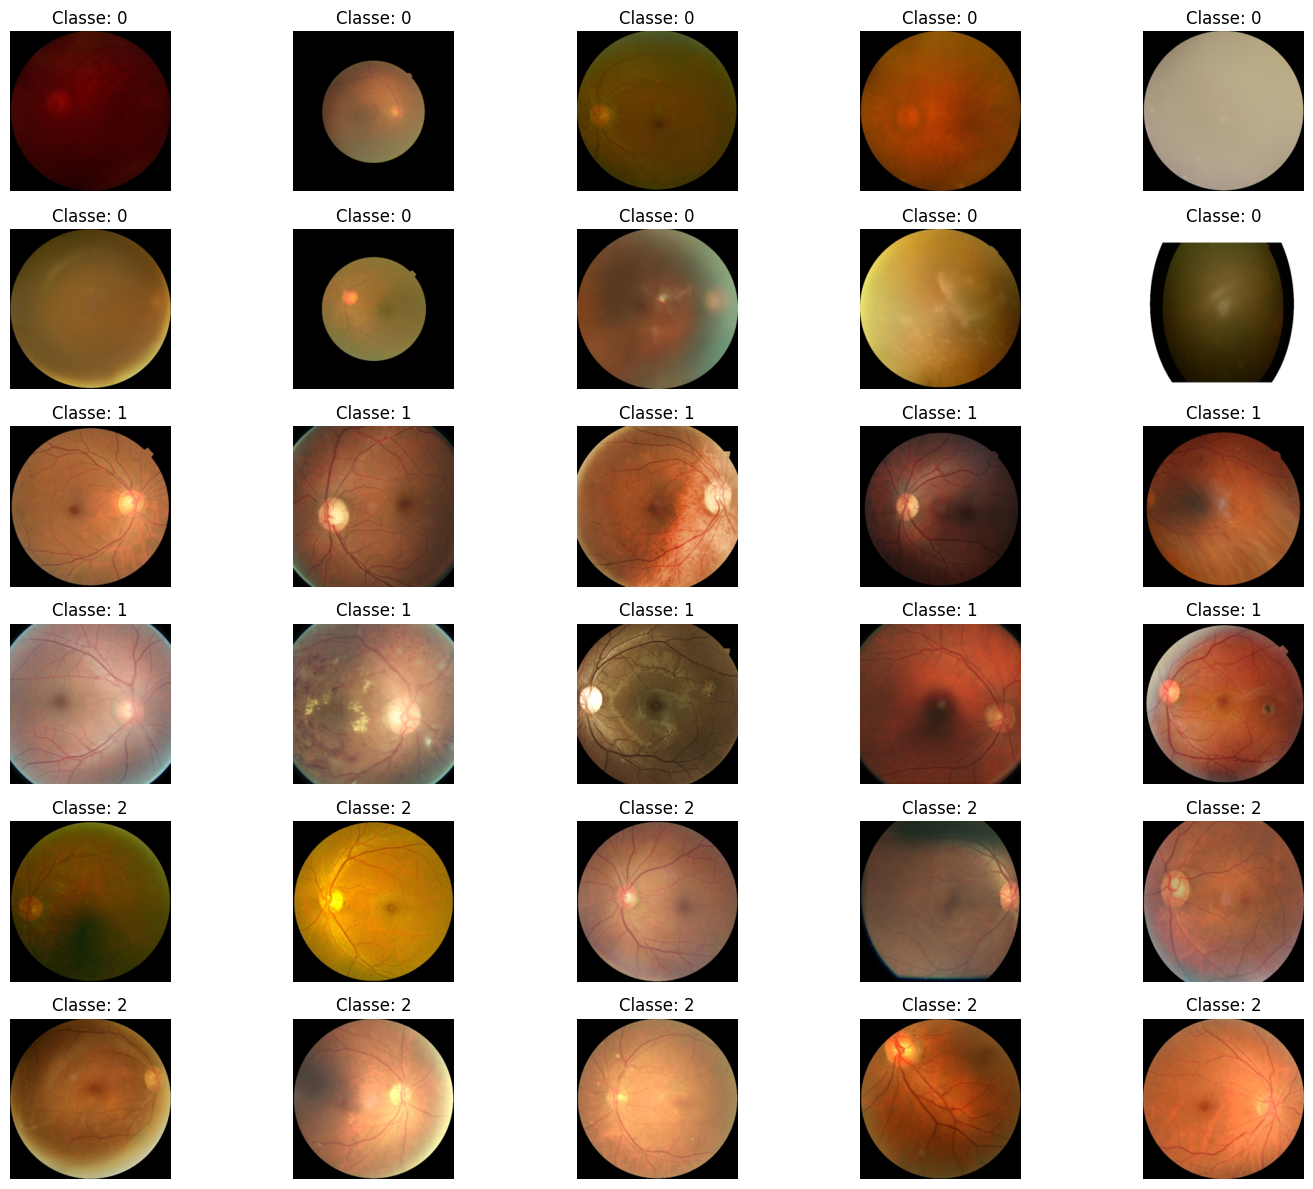

In [7]:
# Índices das imagens de cada classe
idx_classe_0 = np.where(y == 0)[0]
idx_classe_1 = np.where(y == 1)[0]
idx_classe_2 = np.where(y == 2)[0]

# Amostra aleatória de 10 imagens por classe
amostra_0 = np.random.choice(idx_classe_0, size=10, replace=False)
amostra_1 = np.random.choice(idx_classe_1, size=10, replace=False)
amostra_2 = np.random.choice(idx_classe_2, size=10, replace=False)

# Juntar todas as amostras
amostras = np.concatenate([amostra_0, amostra_1, amostra_2])

# Visualizar 30 imagens: 10 da classe 0, 10 da classe 1 e 10 da classe 2
plt.figure(figsize=(15, 12))

for i, idx in enumerate(amostras):
    plt.subplot(6, 5, i + 1)  # 6 linhas x 5 colunas = 30 imagens
    plt.imshow(X_original[idx])
    plt.title(f"Classe: {y[idx]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

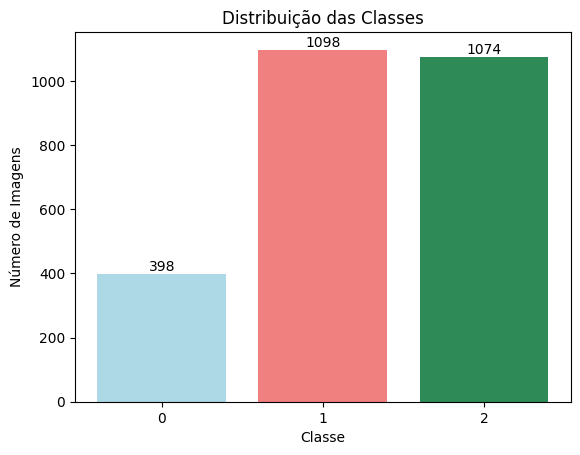

In [8]:
# gráfico de barras para visualizar a distribuição das classes
classes, counts = np.unique(y, return_counts=True)
plt.bar(classes, counts, color=['lightblue', 'lightcoral', 'seagreen'])
plt.xlabel('Classe')
plt.ylabel('Número de Imagens')
plt.title('Distribuição das Classes')
plt.xticks(classes)
for i, (class_label, count) in enumerate(zip(classes, counts)):
    plt.text(i, count + 0.5, str(count), ha='center', va='bottom')
plt.show()

In [9]:
print("Shape de X:", X_original.shape)
print("Shape de y:", y.shape)
print("Classes únicas em y:", np.unique(y))

Shape de X: (2570, 224, 224, 3)
Shape de y: (2570,)
Classes únicas em y: [0 1 2]


Total de imagens: 2570
Total de pacientes únicos: 1454

Distribuição (nº de imagens -> nº de pacientes):
   1 imagem(ns): 346 pacientes
   2 imagem(ns): 1102 pacientes
   3 imagem(ns): 4 pacientes
   4 imagem(ns): 2 pacientes

Pacientes com >1 imagem: 1108
   dos quais com classes DIFERENTES entre olhos: 6


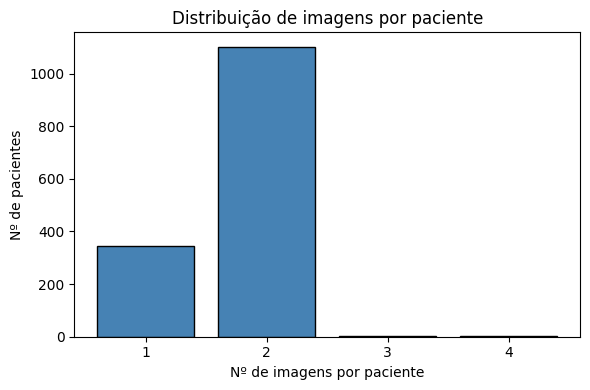

In [10]:

# EDA: análise ao nível do PACIENTE
# As imagens seguem o padrão {id}_{left/right}.jpg, sugerindo
# pares de olhos do mesmo paciente. Verificamos a estrutura.

def id_paciente(nome):
    base = nome.rsplit(".", 1)[0]
    base = re.sub(r'_(left|right)$', '', base, flags=re.I)
    return base

# recolher todos os ficheiros com a respetiva classe
todos = []
for pasta, classe in [(cataract_folder, "cataract"),
                      (diabetic_folder, "diabetic_retinopathy"),
                      (normal_folder, "normal")]:
    for f in sorted(os.listdir(pasta)):
        todos.append((id_paciente(f), classe))

# nº de imagens por paciente
imgs_por_paciente = Counter(p for p, _ in todos)
dist = Counter(imgs_por_paciente.values())

print(f"Total de imagens: {len(todos)}")
print(f"Total de pacientes únicos: {len(imgs_por_paciente)}")
print(f"\nDistribuição (nº de imagens -> nº de pacientes):")
for n_imgs in sorted(dist):
    print(f"   {n_imgs} imagem(ns): {dist[n_imgs]} pacientes")

# verificar se os olhos do mesmo paciente partilham classe
classes_por_paciente = defaultdict(set)
for p, c in todos:
    classes_por_paciente[p].add(c)

multi = [p for p, cs in classes_por_paciente.items()
         if imgs_por_paciente[p] > 1]
discordantes = [p for p in multi if len(classes_por_paciente[p]) > 1]
print(f"\nPacientes com >1 imagem: {len(multi)}")
print(f"   dos quais com classes DIFERENTES entre olhos: {len(discordantes)}")

# gráfico da distribuição
plt.figure(figsize=(6, 4))
plt.bar([str(k) for k in sorted(dist)], [dist[k] for k in sorted(dist)],
        color="steelblue", edgecolor="black")
plt.title("Distribuição de imagens por paciente")
plt.xlabel("Nº de imagens por paciente")
plt.ylabel("Nº de pacientes")
plt.tight_layout()
plt.show()

## 2 — Preparação dos dados
---
Normalização das imagens
Codificação das labels
Divisão treino, validação e teste

Nesta fase foi realizada a preparação dos dados para treino dos modelos de Deep Learning.

As imagens foram normalizadas para o intervalo [0,1], permitindo uma aprendizagem mais estável e eficiente da rede neuronal.

Posteriormente, os dados foram divididos em conjuntos de treino, validação e teste. Esta divisão permite avaliar corretamente a capacidade de generalização do modelo em dados nunca observados durante o treino.

Por fim, as labels foram convertidas para o formato one-hot encoding, adequado para problemas de classificação multiclasse.

In [11]:
# Normalização das imagens

X = X_original.astype("float32") / 255.0

print("Valor mínimo:", X.min())
print("Valor máximo:", X.max())

Valor mínimo: 0.0
Valor máximo: 1.0


In [12]:
# Conversão dos labels para inteiro

y = y.astype(int)

In [13]:
# As labels já se encontram codificadas (0, 1 e 2)

class_names = ["Cataract", "Diabetic Retinopathy", "Normal"]

y_encoded = y.copy()

print("Classes:", class_names)
print("Labels únicas:", np.unique(y_encoded))

Classes: ['Cataract', 'Diabetic Retinopathy', 'Normal']
Labels únicas: [0 1 2]


# 3. Metodologia
A abordagem metodológica divide-se na preparação rigorosa dos dados e no desenvolvimento sequencial de duas arquiteturas convolucionais: uma rede *Baseline* para estabelecer o desempenho de referência e uma rede *Regularizada* para mitigar o sobreajuste (*overfitting*).

## 3.1 Pré-processamento e Divisão dos Dados

Os dados são divididos em três conjuntos independentes:
- **Treino** — para o ajuste dos pesos do modelo;
- **Validação** — para monitorização do treino, *early stopping* e seleção de
  hiperparâmetros;
- **Teste** — para a avaliação final, intocado durante o treino, simulando o
  desempenho do sistema perante novos exames.

A divisão é feita ao nível do **paciente**, e não da imagem. Como o conjunto contém
pares de olhos do mesmo paciente (esquerdo e direito), um split aleatório por imagem
colocaria, com elevada probabilidade, os dois olhos de um indivíduo em conjuntos
diferentes. Dada a semelhança visual entre olhos do mesmo paciente, isso introduziria
*data leakage* e inflaria artificialmente as métricas de teste.

Para o evitar, utilizámos um *split* **estratificado por grupos**
(`StratifiedGroupKFold`), garantindo simultaneamente que (i) todas as imagens de um
paciente permanecem no mesmo conjunto e (ii) as proporções das três classes são
preservadas em cada conjunto. A divisão resultante (~60% treino, ~20% validação,
~20% teste) mantém as 2570 imagens, sem exclusão de dados.

In [14]:
# SPLIT POR PACIENTE (evita leakage de olhos emparelhados)

def id_paciente(nome):
    base = nome.rsplit(".", 1)[0]
    base = re.sub(r'_(left|right)$', '', base, flags=re.I)
    return base

# Build groups from the SAME filename sequence that produced X_original,
# instead of re-listing the folders (which can reorder independently).
groups = np.array([id_paciente(f) for f in nomes_ficheiros])

# Alignment check. The old assert compared only lengths, which stay equal
# even when the order changes -- it could never catch the real failure.
# This compares the class implied by each file's source folder against y,
# element by element, so a reordering is caught immediately.
assert len(groups) == len(X_original), \
    f"groups ({len(groups)}) != X_original ({len(X_original)})"
assert np.array_equal(labels_ficheiros, y), \
    "ordem dos ficheiros desalinhada com y — groups/X_original não correspondem!"
assert len(nomes_ficheiros) == len(X_original), \
    "nomes_ficheiros e X_original têm comprimentos diferentes!"

# 2. Primeiro split: separar TESTE (~20%)
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
trainval_idx, test_idx = next(sgkf.split(X_original, y, groups))

X_trainval, X_test = X_original[trainval_idx], X_original[test_idx]
y_trainval, y_test = y[trainval_idx], y[test_idx]
groups_trainval    = groups[trainval_idx]

# 3. Segundo split: separar VALIDAÇÃO (~20% do total) do treino
sgkf2 = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED)
train_idx, val_idx = next(sgkf2.split(X_trainval, y_trainval, groups_trainval))

X_train, X_val = X_trainval[train_idx], X_trainval[val_idx]
y_train, y_val = y_trainval[train_idx], y_trainval[val_idx]

In [15]:
# verificação se split foi bem sucedido

g_train = set(groups_trainval[train_idx])
g_val   = set(groups_trainval[val_idx])
g_test  = set(groups[test_idx])

print("Pacientes -> treino:", len(g_train), "| val:", len(g_val), "| teste:", len(g_test))
print("Sobreposição treino/teste:", len(g_train & g_test))
print("Sobreposição treino/val:  ", len(g_train & g_val))
print("Sobreposição val/teste:   ", len(g_val & g_test))

print("\nImagens -> treino:", len(X_train), "| val:", len(X_val), "| teste:", len(X_test))
print("Classes treino:", np.bincount(y_train))
print("Classes val:   ", np.bincount(y_val))
print("Classes teste: ", np.bincount(y_test))

Pacientes -> treino: 873 | val: 292 | teste: 289
Sobreposição treino/teste: 0
Sobreposição treino/val:   0
Sobreposição val/teste:    0

Imagens -> treino: 1541 | val: 522 | teste: 507
Classes treino: [241 654 646]
Classes val:    [ 75 226 221]
Classes teste:  [ 82 218 207]


In [16]:
# Verificação da escala dos pixels (antes de treinar)
print("Intervalo de valores dos pixels")
print(f"  treino     -> min: {X_train.min():.4f}   max: {X_train.max():.4f}")
print(f"  validação  -> min: {X_val.min():.4f}   max: {X_val.max():.4f}")
print(f"  teste      -> min: {X_test.min():.4f}   max: {X_test.max():.4f}")
print(f"Formato dos dados (X): {X.shape}")
print(f"  dtype: {X_train.dtype}")


Intervalo de valores dos pixels
  treino     -> min: 0.0000   max: 255.0000
  validação  -> min: 0.0000   max: 255.0000
  teste      -> min: 0.0000   max: 255.0000
Formato dos dados (X): (2570, 224, 224, 3)
  dtype: uint8


In [17]:
# verificação de exemplo de array de pixeis de imagem do dataset
print(X_train[1])

[[[0 0 0]
  [0 0 0]
  [0 0 0]
  ...
  [0 0 0]
  [0 0 0]
  [0 0 0]]

 [[0 0 0]
  [0 0 0]
  [0 0 0]
  ...
  [0 0 0]
  [0 0 0]
  [0 0 0]]

 [[0 0 0]
  [0 0 0]
  [0 0 0]
  ...
  [0 0 0]
  [0 0 0]
  [0 0 0]]

 ...

 [[0 0 0]
  [0 0 0]
  [0 0 0]
  ...
  [0 0 0]
  [0 0 0]
  [0 0 0]]

 [[0 0 0]
  [0 0 0]
  [0 0 0]
  ...
  [0 0 0]
  [0 0 0]
  [0 0 0]]

 [[0 0 0]
  [0 0 0]
  [0 0 0]
  ...
  [0 0 0]
  [0 0 0]
  [0 0 0]]]


## 3.2 CNN Baseline

Como ponto de partida, desenvolvemos uma CNN simples treinada de raiz, que serve
de referência para avaliar o ganho das arquiteturas mais complexas (transfer learning)
exploradas mais à frente.

A arquitetura segue a estrutura convolucional clássica: três blocos `Conv2D + MaxPooling`
com número crescente de filtros (32 → 64 → 128), seguidos de uma camada densa e da
camada de saída com 3 neurónios e ativação *softmax*, correspondente às três classes
(*cataract*, *diabetic_retinopathy*, *normal*).

Aplicámos *early stopping* sobre a *loss* de validação para evitar sobreajuste e
restaurar os melhores pesos. Esta primeira versão é treinada **sem** tratamento do
desequilíbrio de classes, servindo de termo de comparação para a versão seguinte.

In [18]:
# Registo centralizado de modelos treinados para avaliação comparativa.
# Cada entrada guarda: (nome, modelo, history, X_teste, X_treino, y_treino)
# X_treino/y_treino são opcionais — se não fornecidos, assume X_train/y_train (CNNs).
# Para modelos TL, devem ser passados explicitamente X_train_tl/y_train_tl.
# A deduplicação por nome permite re-correr células sem duplicar entradas.

modelos_treinados = []

def adicionar_modelo(nome, modelo, history, X_teste, X_treino=None, y_treino=None):
    global modelos_treinados
    # remover entrada anterior com o mesmo nome (evita duplicados)
    modelos_treinados = [m for m in modelos_treinados if m[0] != nome]
    modelos_treinados.append((
        nome, modelo, history, X_teste,
        X_treino if X_treino is not None else X_train,
        y_treino if y_treino is not None else y_train,
    ))
    print(f"Adicionado: {nome}  (total: {len(modelos_treinados)})")

In [19]:
# Limpar a sessão do TensorFlow para evitar conflitos com modelos anteriores
tf.keras.backend.clear_session()
# Definir seed para garantir reprodutibilidade dos resultados
tf.keras.utils.set_random_seed(SEED)

# CNN Baseline
# Arquitectura de referência: 3 blocos Conv2D + MaxPooling com filtros crescentes
# (32 → 64 → 128), seguidos de uma camada densa e softmax a 3 classes.


model_baseline = models.Sequential([
    layers.Input(shape=X_train.shape[1:]),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dense(3, activation="softmax")
])

# Compilação do modelo
model_baseline.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# early stop para evitar overfitting e restaurar os melhores pesos
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Treino do modelo baseline
baseline_history = model_baseline.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
    callbacks=[early_stop],
    verbose=2
)
adicionar_modelo("Baseline (sem class weight)", model_baseline, baseline_history, X_test)


Epoch 1/20
49/49 - 7s - 152ms/step - accuracy: 0.7521 - loss: 11.8558 - val_accuracy: 0.8966 - val_loss: 0.3096
Epoch 2/20
49/49 - 2s - 42ms/step - accuracy: 0.8748 - loss: 0.3346 - val_accuracy: 0.9042 - val_loss: 0.2861
Epoch 3/20
49/49 - 2s - 43ms/step - accuracy: 0.8858 - loss: 0.2849 - val_accuracy: 0.9138 - val_loss: 0.2431
Epoch 4/20
49/49 - 2s - 42ms/step - accuracy: 0.8981 - loss: 0.2650 - val_accuracy: 0.9100 - val_loss: 0.2625
Epoch 5/20
49/49 - 2s - 42ms/step - accuracy: 0.8923 - loss: 0.2579 - val_accuracy: 0.9023 - val_loss: 0.2092
Epoch 6/20
49/49 - 2s - 41ms/step - accuracy: 0.9014 - loss: 0.2903 - val_accuracy: 0.9023 - val_loss: 0.3691
Epoch 7/20
49/49 - 2s - 41ms/step - accuracy: 0.9033 - loss: 0.2483 - val_accuracy: 0.8774 - val_loss: 0.4020
Epoch 8/20
49/49 - 2s - 41ms/step - accuracy: 0.9208 - loss: 0.2153 - val_accuracy: 0.9119 - val_loss: 0.2540
Epoch 9/20
49/49 - 2s - 41ms/step - accuracy: 0.9221 - loss: 0.1870 - val_accuracy: 0.9004 - val_loss: 0.2334
Epoch 10

### 3.2.1 Baseline + Classweight

O conjunto de dados é desequilibrado: a classe *cataract* representa apenas ~15% das
imagens, contra ~42% para *diabetic_retinopathy* e *normal*. Num modelo treinado sem
correção, esta sub-representação tende a penalizar a deteção da classe minoritária.

Este aspeto é especialmente relevante para o nosso caso de uso (referenciação
hospitalar): uma catarata não detetada corresponde a um doente que não é encaminhado
para avaliação especializada. Por isso, a deteção da classe minoritária — medida pelo
*recall* da *cataract* — é uma prioridade.

Para mitigar o desequilíbrio, treinámos uma segunda versão do baseline com **pesos de
classe** (`class_weight="balanced"`), que atribui a cada classe um peso inversamente
proporcional à sua frequência, penalizando mais os erros na classe minoritária.
Comparamos as duas versões com foco no *recall* da *cataract* para fundamentar a
decisão de adotar (ou não) esta técnica.

In [20]:
# Calcular pesos de classe para compensar o desequilíbrio do dataset
# "balanced": peso inversamente proporcional à frequência de cada classe
# Catarata (classe minoritária) receberá o peso mais elevado
classes = np.unique(y_train)
pesos   = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train,
)
# converter para dicionário {label: peso} — formato esperado pelo Keras
class_weight = {int(c): float(w) for c, w in zip(classes, pesos)}
print("Pesos por classe:", class_weight)

Pesos por classe: {0: 2.131396957123098, 1: 0.7854230377166157, 2: 0.7951496388028896}


In [21]:
# Limpar a sessão do TensorFlow para evitar conflitos com modelos anteriores
tf.keras.backend.clear_session()
# Definir seed para garantir reprodutibilidade dos resultados
tf.keras.utils.set_random_seed(SEED)

# CNN Baseline com Class Weight
# Arquitectura idêntica ao baseline anterior — a única diferença é o class_weight,
# que penaliza mais os erros na classe minoritária (catarata) durante o treino.

model_baseline_classweight = models.Sequential([
    layers.Input(shape=X_train.shape[1:]),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dense(3, activation="softmax")
])

model_baseline_classweight.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# early stop para evitar overfitting e restaurar os melhores pesos
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

baseline_history_classweight = model_baseline_classweight.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
    callbacks=[early_stop],
    verbose=2,
    class_weight = class_weight,  # penaliza erros na catarata proporcionalmente à sub-representação
)

# adicionar o modelo com class weight à lista de avaliação
adicionar_modelo("Baseline (class weight)", model_baseline_classweight, baseline_history_classweight, X_test)

Epoch 1/20
49/49 - 4s - 83ms/step - accuracy: 0.6684 - loss: 16.3292 - val_accuracy: 0.8697 - val_loss: 0.3821
Epoch 2/20
49/49 - 2s - 42ms/step - accuracy: 0.8404 - loss: 0.4354 - val_accuracy: 0.8870 - val_loss: 0.2964
Epoch 3/20
49/49 - 2s - 42ms/step - accuracy: 0.8384 - loss: 0.4034 - val_accuracy: 0.9004 - val_loss: 0.2646
Epoch 4/20
49/49 - 2s - 42ms/step - accuracy: 0.8559 - loss: 0.3510 - val_accuracy: 0.9023 - val_loss: 0.2521
Epoch 5/20
49/49 - 2s - 42ms/step - accuracy: 0.8787 - loss: 0.3264 - val_accuracy: 0.8697 - val_loss: 0.2997
Epoch 6/20
49/49 - 2s - 42ms/step - accuracy: 0.8968 - loss: 0.2964 - val_accuracy: 0.8448 - val_loss: 0.3465
Epoch 7/20
49/49 - 2s - 42ms/step - accuracy: 0.9046 - loss: 0.2725 - val_accuracy: 0.9004 - val_loss: 0.5045
Epoch 8/20
49/49 - 2s - 41ms/step - accuracy: 0.8942 - loss: 0.2754 - val_accuracy: 0.8736 - val_loss: 0.2972
Epoch 9/20
49/49 - 2s - 41ms/step - accuracy: 0.9040 - loss: 0.2736 - val_accuracy: 0.8640 - val_loss: 0.3235
Adicionad

### 3.3 CNN Regularizada
#### Afinação da Regularização

Tendo fixado o baseline com pesos de classe como modelo de referência, exploramos de
forma sistemática o efeito da **regularização**, motivados pela ligeira folga entre o
desempenho em treino e em validação observada nas curvas anteriores.

Testamos duas técnicas de regularização complementares através de um *grid search*:

- **Regularização L2**: penaliza pesos de grande magnitude, favorecendo soluções mais
  suaves e reduzindo a dependência do modelo em características específicas do conjunto
  de treino.
- **Dropout**: desativa aleatoriamente uma fração de neurónios durante o treino,
  evitando a coadaptação entre neurónios e promovendo representações mais robustas.

As duas técnicas atuam em planos distintos — o L2 sobre a magnitude dos pesos, o dropout
sobre a estrutura da rede — pelo que são frequentemente combinadas. Realizámos uma
pesquisa em grelha reduzida sobre os dois parâmetros, incluindo a configuração **sem
regularização** como referência, e mantendo fixos os restantes elementos (arquitetura,
*learning rate*, pesos de classe e *early stopping*) para isolar o efeito da
regularização.

A seleção é feita com base no **F1-*macro*** na validação — e não na *accuracy* — por
ponderar as três classes por igual, evitando que o desempenho nas classes maioritárias
mascare a deteção da *cataract*, prioritária para o nosso caso de uso.

In [22]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

def build_model(l2_value=0.0, dropout_value=0.0):
    """
    Constrói uma CNN com 3 blocos Conv2D + MaxPooling e uma camada densa.
    Regularização L2 e Dropout configuráveis — se l2_value=0 não aplica regularização,
    permitindo incluir a configuração sem regularização como referência no grid search.
    """
    reg = regularizers.l2(l2_value) if l2_value > 0 else None  # sem reg se l2=0
    model = models.Sequential([
        layers.Input(shape=X_train.shape[1:]),
        layers.Conv2D(32,  (3,3), activation="relu", kernel_regularizer=reg),
        layers.MaxPooling2D((2,2)),
        layers.Conv2D(64,  (3,3), activation="relu", kernel_regularizer=reg),
        layers.MaxPooling2D((2,2)),
        layers.Conv2D(128, (3,3), activation="relu", kernel_regularizer=reg),
        layers.MaxPooling2D((2,2)),
        layers.Flatten(),
        layers.Dense(128, activation="relu", kernel_regularizer=reg),
        layers.Dropout(dropout_value),
        layers.Dense(3, activation="softmax"),
    ])
    model.compile(optimizer="adam",
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

In [23]:
def cnn_grid_search():
    """
    Grid search sobre L2 e Dropout para a CNN treinada de raiz.
    Testa 9 combinações (3 valores de L2 × 3 valores de Dropout).
    Seleciona com base no F1-macro na validação — mais robusto ao
    desequilíbrio de classes do que a accuracy.
    """
    l2_values      = [0, 0.0001, 0.001]
    dropout_values = [0, 0.3, 0.5]
    resultados     = []

    for l2_v, drop_v in product(l2_values, dropout_values):
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(SEED)
        print(f"=== L2={l2_v}  dropout={drop_v} ===")

        model = build_model(l2_v, drop_v)
        es    = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
        model.fit(X_train, y_train,
                  validation_data=(X_val, y_val),
                  epochs=15, batch_size=32,
                  class_weight=class_weight,
                  callbacks=[es], verbose=0)

        # avaliar na validação — critério de selecção: F1-macro
        y_pred  = np.argmax(model.predict(X_val, verbose=0), axis=1)
        f1m     = f1_score(y_val, y_pred, average="macro")
        rec_cat = recall_score(y_val, y_pred, labels=[0], average="macro")
        resultados.append({"l2": l2_v, "dropout": drop_v,
                           "f1_macro": float(f1m), "recall_catarata": float(rec_cat)})
        print(f"   F1-macro={f1m:.4f}  recall_catarata={rec_cat:.4f}")

    # ordenar por F1-macro e mostrar ranking completo
    resultados.sort(key=lambda r: r["f1_macro"], reverse=True)
    print("\n===== RANKING =====")
    for r in resultados:
        print(f"F1={r['f1_macro']:.4f}  rec_cat={r['recall_catarata']:.4f}"
              f"  <-  L2={r['l2']}  dropout={r['dropout']}")
    return resultados[0]  # devolver os melhores hiperparâmetros

In [24]:
def aplicar_melhor_cnn(best_params):
    """
    Treina o modelo CNN final com os melhores hiperparâmetros do grid search.
    Usa learning rate reduzido (0.0005) e mais epochs face ao grid search,
    permitindo uma convergência mais fina.
    """
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    model = build_model(best_params["l2"], best_params["dropout"])
    model.compile(optimizer=optimizers.Adam(learning_rate=0.0005),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])

    es = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

    history = model.fit(X_train, y_train,
                        validation_data=(X_val, y_val),
                        epochs=30, batch_size=32,
                        class_weight=class_weight,
                        callbacks=[es], verbose=2)

    adicionar_modelo("Regularizado", model, history, X_test, X_train, y_train)
    return model, history

In [25]:
# ── Executar Grid Search e treinar o modelo final ────────────
best_cnn = cnn_grid_search()
model_regularized, regularized_history = aplicar_melhor_cnn(best_cnn)

=== L2=0  dropout=0 ===
   F1-macro=0.8245  recall_catarata=0.4667
=== L2=0  dropout=0.3 ===
   F1-macro=0.8120  recall_catarata=0.4400
=== L2=0  dropout=0.5 ===
   F1-macro=0.8225  recall_catarata=0.4133
=== L2=0.0001  dropout=0 ===
   F1-macro=0.8380  recall_catarata=0.5867
=== L2=0.0001  dropout=0.3 ===
   F1-macro=0.8345  recall_catarata=0.4933
=== L2=0.0001  dropout=0.5 ===
   F1-macro=0.8110  recall_catarata=0.3867
=== L2=0.001  dropout=0 ===
   F1-macro=0.9131  recall_catarata=0.8400
=== L2=0.001  dropout=0.3 ===
   F1-macro=0.8376  recall_catarata=0.5467
=== L2=0.001  dropout=0.5 ===
   F1-macro=0.8195  recall_catarata=0.6267

===== RANKING =====
F1=0.9131  rec_cat=0.8400  <-  L2=0.001  dropout=0
F1=0.8380  rec_cat=0.5867  <-  L2=0.0001  dropout=0
F1=0.8376  rec_cat=0.5467  <-  L2=0.001  dropout=0.3
F1=0.8345  rec_cat=0.4933  <-  L2=0.0001  dropout=0.3
F1=0.8245  rec_cat=0.4667  <-  L2=0  dropout=0
F1=0.8225  rec_cat=0.4133  <-  L2=0  dropout=0.5
F1=0.8195  rec_cat=0.6267  <-  

## 3.4 Transfer Learning

Após estabelecer a referência com as CNNs treinadas de raiz, exploramos uma abordagem
mais poderosa: o **Transfer Learning**. Em vez de inicializar os pesos aleatoriamente,
partimos de redes pré-treinadas no **ImageNet** — um dataset com mais de 1 milhão de
imagens e 1000 classes — que já aprenderam representações visuais ricas e generalizáveis
(bordos, texturas, padrões complexos).

O treino é dividido em duas fases complementares, aplicadas a cada modelo:

- **Feature Extraction**: a base convolucional fica completamente congelada; apenas a
  cabeça de classificação adicionada é treinada. Permite aprender um mapeamento das
  features ImageNet para as nossas três classes sem corromper os pesos pré-treinados.

- **Fine-Tuning**: as últimas camadas da base são descongeladas e o modelo é treinado
  com um *learning rate* muito mais baixo, ajustando as representações de alto nível ao
  domínio específico das imagens oftalmológicas.

Em ambas as fases, mantemos os **pesos de classe** para preservar a sensibilidade na
deteção da *cataract*, classe minoritária e prioritária no contexto do Use Case 3.

Serão explorados dois modelos de referência na literatura: EfficientNetB0 e  ResNet50

Os modelos pré-treinados utilizam o seu próprio esquema de normalização interno, pelo que os dados são fornecidos com pixels em [0, 255] em vez da normalização [0, 1] aplicada nas CNNs treinadas de raiz.

In [26]:
# Split para Transfer Learning (pixels em [0, 255] — sem normalização prévia)
# Os modelos TL têm pré-processamento interno próprio, pelo que os dados
# são fornecidos em escala original. Os índices são idênticos ao split
# das CNNs (mesmo SEED e n_splits), garantindo conjuntos equivalentes.

sgkf_tl = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
trainval_idx_tl, test_idx_tl = next(sgkf_tl.split(X_original, y, groups))

X_trainval_tl      = X_original[trainval_idx_tl]
X_test_tl          = X_original[test_idx_tl]
y_trainval_tl      = y[trainval_idx_tl]
y_test_tl          = y[test_idx_tl]
groups_trainval_tl = groups[trainval_idx_tl]

sgkf2_tl = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED)
train_idx_tl, val_idx_tl = next(sgkf2_tl.split(X_trainval_tl, y_trainval_tl, groups_trainval_tl))

# converter para float32 sem normalizar — escala [0, 255] mantida
X_train_tl = X_trainval_tl[train_idx_tl].astype("float32")
X_val_tl   = X_trainval_tl[val_idx_tl].astype("float32")
y_train_tl = y_trainval_tl[train_idx_tl]
y_val_tl   = y_trainval_tl[val_idx_tl]
X_test_tl  = X_test_tl.astype("float32")

print(f"Treino: {X_train_tl.shape}  min={X_train_tl.min():.1f}  max={X_train_tl.max():.1f}")
print(f"Val:    {X_val_tl.shape}")
print(f"Teste:  {X_test_tl.shape}")

Treino: (1541, 224, 224, 3)  min=0.0  max=255.0
Val:    (522, 224, 224, 3)
Teste:  (507, 224, 224, 3)


## 3.4.1 EfficientNetB0
O **EfficientNetB0** é a variante base da família EfficientNet, uma arquitetura que
escala as dimensões da rede (profundidade, largura e resolução) de forma composta e
controlada, obtendo melhor desempenho com menos parâmetros do que arquiteturas
tradicionais como VGG ou ResNet.

É amplamente utilizado em tarefas de classificação de imagens médicas pela sua
eficiência computacional e pela qualidade das representações aprendidas no ImageNet,
que transferem bem para domínios especializados com datasets de dimensão limitada —
como o nosso.

In [27]:
# EfficientNetB0 — Feature Extraction
# Base convolucional congelada: apenas a cabeça de classificação é treinada.
# O pré-processamento da EfficientNetB0 é aplicado internamente pela própria base.

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

base_model = EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)
base_model.trainable = False  # congelar todos os pesos pré-treinados

inputs  = tf.keras.Input(shape=(224, 224, 3))
x       = base_model(inputs, training=False)
x       = tf.keras.layers.GlobalAveragePooling2D()(x)
x       = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(3, activation="softmax")(x)

model_effnet = Model(inputs, outputs)

model_effnet.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

es = EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)

history_effnet_phase1 = model_effnet.fit(
    X_train_tl, y_train_tl,
    validation_data=(X_val_tl, y_val_tl),
    epochs=15,
    batch_size=32,
    class_weight=class_weight,
    callbacks=[es],
    verbose=2
)
adicionar_modelo("EfficientNetB0 (feature extraction)", model_effnet, history_effnet_phase1, X_test_tl, X_train_tl, y_train_tl)


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/15
49/49 - 17s - 342ms/step - accuracy: 0.6742 - loss: 0.6947 - val_accuracy: 0.8640 - val_loss: 0.4453
Epoch 2/15
49/49 - 3s - 62ms/step - accuracy: 0.8144 - loss: 0.4283 - val_accuracy: 0.8966 - val_loss: 0.3472
Epoch 3/15
49/49 - 3s - 63ms/step - accuracy: 0.8754 - loss: 0.3519 - val_accuracy: 0.9195 - val_loss: 0.2943
Epoch 4/15
49/49 - 3s - 62ms/step - accuracy: 0.8832 - loss: 0.3245 - val_accuracy: 0.9253 - val_loss: 0.2642
Epoch 5/15
49/49 - 3s - 62ms/step - accuracy: 0.8936 - loss: 0.2863 - val_accuracy: 0.9330 - val_loss: 0.2327
Epoch 6/15
49/49 - 3s - 62ms/step - accuracy: 0.9111 - loss: 0.2649 - val_accuracy: 0.9406 - val_loss: 0.2145
Epoch 7/15
49/49 - 3s - 63ms/step - accuracy: 0.9202 - loss: 0.2596 - val_accuracy: 0.9425 - val_loss: 0.1993
Epoch 8/15
49/49 - 3s - 63ms/step - accuracy: 0.9286 - loss: 0.2356 - val_accuracy: 0.9521 - val_loss: 0.1858
Epoch 9/15
49/49 - 3s - 63ms/step - accuracy: 0.9221 - loss: 0.2303

### Fine-Tuning

Partindo dos pesos obtidos na fase de Feature Extraction, procedemos ao Fine-Tuning
da EfficientNetB0. As últimas camadas da base convolucional foram descongeladas e
re-treinadas com um *learning rate* muito mais baixo, de forma a ajustar as
representações de alto nível ao domínio específico das imagens oftalmológicas sem
corromper os pesos pré-treinados.

O *grid search* explorou 9 combinações de *learning rate* ∈ {1e-4, 1e-5, 1e-6} e
número de camadas descongeladas ∈ {10, 30, 50}, avaliadas pelo **F1-macro** na
validação. A melhor combinação encontrada foi **LR=1e-4** com **50 camadas
descongeladas** (F1=0.9779), sugerindo que um ajuste mais profundo da rede beneficia
a adaptação ao domínio oftalmológico.

In [28]:

def fine_tuning_grid_search(model, base_model, nome_modelo, phase1_weights):
    """
    Grid search sobre learning_rate e n_layers_unfrozen para fine-tuning.
    Para cada combinação, parte sempre dos pesos da fase 1 (feature extraction)
    para garantir comparação justa. Seleciona com base no F1-macro na validação.
    """
    learning_rates = [1e-4, 1e-5, 1e-6]
    n_layers_list  = [10, 30, 50]

    resultados = []

    for lr, n_layers in product(learning_rates, n_layers_list):
        tf.keras.utils.set_random_seed(SEED)
        print(f"=== {nome_modelo} | LR={lr}  layers={n_layers} ===")

        # restaurar pesos da fase 1 para partir do mesmo ponto em cada iteração
        model.set_weights(phase1_weights)

        # descongelar apenas as últimas n_layers da base convolucional
        base_model.trainable = True
        for layer in base_model.layers[:-n_layers]:
            layer.trainable = False

        model.compile(
            optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"]
        )

        es = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

        model.fit(
            X_train_tl, y_train_tl,
            validation_data=(X_val_tl, y_val_tl),
            epochs=10,
            batch_size=32,
            class_weight=class_weight,
            callbacks=[es],
            verbose=0
        )

        # avaliar na validação — critério de selecção: F1-macro
        y_pred  = np.argmax(model.predict(X_val_tl, verbose=0), axis=1)
        f1m     = f1_score(y_val_tl, y_pred, average="macro")
        rec_cat = recall_score(y_val_tl, y_pred, labels=[0], average="macro")

        resultados.append({
            "lr": lr, "n_layers": n_layers,
            "f1_macro": float(f1m), "recall_catarata": float(rec_cat)
        })
        print(f"   F1-macro={f1m:.4f}  recall_catarata={rec_cat:.4f}")

        # congelar novamente antes da próxima iteração
        base_model.trainable = False

    # ordenar por F1-macro e mostrar ranking completo
    resultados.sort(key=lambda r: r["f1_macro"], reverse=True)
    print(f"\n===== RANKING — {nome_modelo} =====")
    for r in resultados:
        print(f"F1={r['f1_macro']:.4f}  rec_cat={r['recall_catarata']:.4f}  <-  LR={r['lr']}  layers={r['n_layers']}")

    return resultados[0]  # devolver os melhores hiperparâmetros

In [29]:
def aplicar_melhor_fine_tuning(model, base_model, best_params, nome_modelo, phase1_weights):
    """
    Treina o modelo final com os melhores hiperparâmetros encontrados no grid search.
    Restaura os pesos da fase 1, descongela as últimas n_layers e treina com LR reduzido.
    """
    # restaurar pesos da feature extraction para partir do mesmo ponto
    model.set_weights(phase1_weights)

    # descongelar apenas as últimas n_layers da base
    base_model.trainable = True
    for layer in base_model.layers[:-best_params["n_layers"]]:
        layer.trainable = False

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=best_params["lr"]),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    es = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

    history = model.fit(
        X_train_tl, y_train_tl,
        validation_data=(X_val_tl, y_val_tl),
        epochs=20,
        batch_size=32,
        class_weight=class_weight,
        callbacks=[es],
        verbose=2
    )

    adicionar_modelo(f"{nome_modelo} (fine-tuned)", model, history, X_test_tl, X_train_tl, y_train_tl)
    return history

In [30]:
# EfficientNetB0 — Fine-Tuning
# Guardar pesos da fase 1 antes de descongelar camadas.
# O grid search selecciona o melhor LR e número de camadas a descongelar.

phase1_weights_effnet = model_effnet.get_weights()

best_effnet = fine_tuning_grid_search(
    model_effnet, base_model,
    "EfficientNetB0",
    phase1_weights_effnet
    )
history_effnet_ft = aplicar_melhor_fine_tuning(
    model_effnet,
    base_model,
    best_effnet,
    "EfficientNetB0",
    phase1_weights_effnet
    )

=== EfficientNetB0 | LR=0.0001  layers=10 ===
   F1-macro=0.9594  recall_catarata=0.9733
=== EfficientNetB0 | LR=0.0001  layers=30 ===
   F1-macro=0.9708  recall_catarata=0.9733
=== EfficientNetB0 | LR=0.0001  layers=50 ===
   F1-macro=0.9808  recall_catarata=0.9733
=== EfficientNetB0 | LR=1e-05  layers=10 ===
   F1-macro=0.9528  recall_catarata=0.9733
=== EfficientNetB0 | LR=1e-05  layers=30 ===
   F1-macro=0.9471  recall_catarata=0.9600
=== EfficientNetB0 | LR=1e-05  layers=50 ===
   F1-macro=0.9568  recall_catarata=0.9600
=== EfficientNetB0 | LR=1e-06  layers=10 ===
   F1-macro=0.9355  recall_catarata=0.9733
=== EfficientNetB0 | LR=1e-06  layers=30 ===
   F1-macro=0.8841  recall_catarata=0.9600
=== EfficientNetB0 | LR=1e-06  layers=50 ===
   F1-macro=0.8802  recall_catarata=0.9600

===== RANKING — EfficientNetB0 =====
F1=0.9808  rec_cat=0.9733  <-  LR=0.0001  layers=50
F1=0.9708  rec_cat=0.9733  <-  LR=0.0001  layers=30
F1=0.9594  rec_cat=0.9733  <-  LR=0.0001  layers=10
F1=0.9568  

## 3.4.2 ResNet50

A **ResNet50** (Residual Network) é uma arquitetura de 50 camadas que introduziu as
**ligações residuais** (*skip connections*): atalhos que permitem ao gradiente fluir
diretamente entre camadas não adjacentes, resolvendo o problema de degradação do
treino em redes muito profundas. É uma das arquiteturas mais utilizadas em visão
computacional e um benchmark comum em classificação de imagens médicas.

Ao contrário do EfficientNetB0, a ResNet50 requer um pré-processamento específico
(*mean subtraction* por canal RGB), aplicado internamente no modelo.

In [31]:
# ResNet50 — Feature Extraction
# Base convolucional congelada: apenas a cabeça de classificação é treinada.
# O pré-processamento específico da ResNet (mean subtraction por canal RGB)
# é aplicado internamente via Lambda layer.

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

base_model_resnet = ResNet50(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)
base_model_resnet.trainable = False  # congelar todos os pesos pré-treinados

inputs = tf.keras.Input(shape=(224, 224, 3))
x = tf.keras.layers.Lambda(
    lambda img: tf.keras.applications.resnet50.preprocess_input(img)
)(inputs)  # pré-processamento interno da ResNet
x = base_model_resnet(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(3, activation="softmax")(x)

model_resnet = Model(inputs, outputs)

model_resnet.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

es = EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)

history_resnet_phase1 = model_resnet.fit(
    X_train_tl, y_train_tl,
    validation_data=(X_val_tl, y_val_tl),
    epochs=15,
    batch_size=32,
    class_weight=class_weight,
    callbacks=[es],
    verbose=2
)
adicionar_modelo("ResNet50 (feature extraction)", model_resnet, history_resnet_phase1, X_test_tl, X_train_tl, y_train_tl)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
Epoch 1/15
49/49 - 14s - 283ms/step - accuracy: 0.7171 - loss: 0.6159 - val_accuracy: 0.8851 - val_loss: 0.2992
Epoch 2/15
49/49 - 4s - 88ms/step - accuracy: 0.8469 - loss: 0.3524 - val_accuracy: 0.8966 - val_loss: 0.2434
Epoch 3/15
49/49 - 4s - 88ms/step - accuracy: 0.8735 - loss: 0.3050 - val_accuracy: 0.9080 - val_loss: 0.2184
Epoch 4/15
49/49 - 4s - 89ms/step - accuracy: 0.8910 - loss: 0.2608 - val_accuracy: 0.9310 - val_loss: 0.1861
Epoch 5/15
49/49 - 4s - 89ms/step - accuracy: 0.9098 - loss: 0.2329 - val_accuracy: 0.9368 - val_loss: 0.1783
Epoch 6/15
49/49 - 4s - 89ms/step - accuracy: 0.9241 - loss: 0.2167 - val_accuracy: 0.9425 - val_loss: 0.1709
Epoch 7/15
49/49 - 4s - 89ms/step - accuracy: 0.9234 - loss: 0.1992 - val_accuracy: 0.9540 - val_loss: 0.1468
Epoch 8/15
49/49 - 4s - 89ms/step - accuracy: 0.9332 - loss: 0.1714 - val_accuracy: 0.9540 - val_loss: 0.1440
Epoch 9/15
49/49 - 4s - 89ms/step - accuracy: 0.9455 - loss: 0.1761

### Fine-Tuning

Partindo dos pesos obtidos na fase de Feature Extraction, procedemos ao Fine-Tuning
da ResNet50 seguindo a mesma metodologia aplicada à EfficientNetB0.

O *grid search* explorou 9 combinações de *learning rate* ∈ {1e-4, 1e-5, 1e-6} e
número de camadas descongeladas ∈ {10, 30, 50}, avaliadas pelo **F1-macro** na
validação.

In [32]:
# ResNet50 — Fine-Tuning
# Guardar pesos da fase 1 antes de descongelar camadas.
# O grid search selecciona o melhor LR e número de camadas a descongelar.
phase1_weights_resnet = model_resnet.get_weights()

best_resnet = fine_tuning_grid_search(
    model_resnet,
    base_model_resnet,
    "ResNet50",
    phase1_weights_resnet
    )
history_resnet_ft = aplicar_melhor_fine_tuning(
    model_resnet,
    base_model_resnet,
    best_resnet,
    "ResNet50",
    phase1_weights_resnet
    )

=== ResNet50 | LR=0.0001  layers=10 ===
   F1-macro=0.9702  recall_catarata=0.9467
=== ResNet50 | LR=0.0001  layers=30 ===
   F1-macro=0.9778  recall_catarata=0.9733
=== ResNet50 | LR=0.0001  layers=50 ===
   F1-macro=0.9792  recall_catarata=0.9600
=== ResNet50 | LR=1e-05  layers=10 ===
   F1-macro=0.9693  recall_catarata=0.9733
=== ResNet50 | LR=1e-05  layers=30 ===
   F1-macro=0.9665  recall_catarata=0.9733
=== ResNet50 | LR=1e-05  layers=50 ===
   F1-macro=0.9651  recall_catarata=0.9733
=== ResNet50 | LR=1e-06  layers=10 ===
   F1-macro=0.9648  recall_catarata=0.9733
=== ResNet50 | LR=1e-06  layers=30 ===
   F1-macro=0.9063  recall_catarata=0.9733
=== ResNet50 | LR=1e-06  layers=50 ===
   F1-macro=0.9096  recall_catarata=0.9600

===== RANKING — ResNet50 =====
F1=0.9792  rec_cat=0.9600  <-  LR=0.0001  layers=50
F1=0.9778  rec_cat=0.9733  <-  LR=0.0001  layers=30
F1=0.9702  rec_cat=0.9467  <-  LR=0.0001  layers=10
F1=0.9693  rec_cat=0.9733  <-  LR=1e-05  layers=10
F1=0.9665  rec_cat=0

# 4. Resultados
Nesta secção, avaliamos o desempenho quantitativo e qualitativo das redes neurais desenvolvidas.

## 4.1 Definição de funções para avaliar o desempenho dos modelos

In [33]:
def plot_training_history(history):
    """
    Plota as curvas de Loss e Accuracy de treino e validação ao longo das épocas.
    Permite identificar overfitting (divergência entre treino e validação)
    e monitorizar a convergência do modelo.
    """
    train_loss     = history.history["loss"]
    val_loss       = history.history["val_loss"]
    train_accuracy = history.history["accuracy"]
    val_accuracy   = history.history["val_accuracy"]

    epochs = range(1, len(train_loss) + 1)

    # resumo numérico
    print("Última train accuracy:", train_accuracy[-1])
    print("Última val accuracy:  ", val_accuracy[-1])
    print("Melhor train accuracy:", max(train_accuracy))
    print("Melhor val accuracy:  ", max(val_accuracy))

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(epochs, train_loss, "bo-", label="Training Loss")
    plt.plot(epochs, val_loss,   "ro-", label="Validation Loss")
    plt.title("Training and Validation Loss")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs, train_accuracy, "bo-", label="Training Accuracy")
    plt.plot(epochs, val_accuracy,   "ro-", label="Validation Accuracy")
    plt.title("Training and Validation Accuracy")
    plt.xlabel("Epochs")
    plt.ylabel("Accuracy")
    plt.legend()

    plt.tight_layout()
    plt.show()


In [34]:
# matriz de confusão e relatório de classificação para treino e teste
def avaliar_modelo_multiclasse(modelo, X_train, y_train, X_test, y_test, nome_modelo="Modelo"):
    # Probabilidades previstas
    y_train_pred_probs = modelo.predict(X_train, verbose=0)
    y_train_pred = np.argmax(y_train_pred_probs, axis=1)

    y_test_pred_probs = modelo.predict(X_test, verbose=0)
    y_test_pred = np.argmax(y_test_pred_probs, axis=1)

    # Matrizes de confusão
    cm_train = confusion_matrix(y_train, y_train_pred)
    cm_test = confusion_matrix(y_test, y_test_pred)

    # Plot lado a lado
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    disp_train = ConfusionMatrixDisplay(confusion_matrix=cm_train, display_labels=class_names)
    disp_train.plot(ax=axes[0], cmap="Blues", colorbar=False)
    axes[0].set_title(f"{nome_modelo} - Treino")

    disp_test  = ConfusionMatrixDisplay(confusion_matrix=cm_test,  display_labels=class_names)
    disp_test.plot(ax=axes[1], cmap="Blues", colorbar=False)
    axes[1].set_title(f"{nome_modelo} - Teste")

    plt.tight_layout()
    plt.show()

    # Relatórios
    print(f"=== {nome_modelo} | TREINO ===")
    print(classification_report(y_train, y_train_pred))

    print(f"=== {nome_modelo} | TESTE ===")
    print(classification_report(y_test, y_test_pred))



In [35]:
def plot_roc_pr_curves(modelo, X_t, y_t, class_names, nome_modelo):
    """
    Plota lado a lado a Curva ROC e a Curva Precision-Recall para cada classe
    usando a estratégia One-vs-Rest (OvR).
    - ROC: relação entre Sensibilidade e 1-Especificidade — standard clínico
    - Precision-Recall: mais informativa em datasets desbalanceados como o nosso
    """
    y_pred_probs = modelo.predict(X_t, verbose=0)
    y_test_bin   = label_binarize(y_t, classes=[0, 1, 2])  # binarização OvR
    colors       = ["blue", "red", "green"]

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Curva ROC
    for i, (cls, cor) in enumerate(zip(class_names, colors)):
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_pred_probs[:, i])
        roc_auc     = auc(fpr, tpr)
        axes[0].plot(fpr, tpr, color=cor, label=f"{cls} (AUC={roc_auc:.2f})")
    axes[0].plot([0,1], [0,1], "k--")  # linha de referência — classificador aleatório
    axes[0].set_title(f"Curva ROC — {nome_modelo}")
    axes[0].set_xlabel("1 - Especificidade")
    axes[0].set_ylabel("Sensibilidade")
    axes[0].legend()

    # Curva Precision-Recall
    for i, (cls, cor) in enumerate(zip(class_names, colors)):
        prec, rec, _ = precision_recall_curve(y_test_bin[:, i], y_pred_probs[:, i])
        ap           = average_precision_score(y_test_bin[:, i], y_pred_probs[:, i])
        axes[1].plot(rec, prec, color=cor, label=f"{cls} (AP={ap:.2f})")
    axes[1].set_title(f"Curva Precision-Recall — {nome_modelo}")
    axes[1].set_xlabel("Recall")
    axes[1].set_ylabel("Precision")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

In [36]:
def plot_sensitivity_specificity_threshold(modelo, X_t, y_t, class_names, nome_modelo):
    """
    Para cada classe, plota Sensibilidade e Especificidade em função do threshold.
    Permite analisar o impacto da escolha do threshold de decisão no contexto clínico
    do UC3 — onde o equilíbrio entre detetar doentes e evitar encaminhamentos
    desnecessários é crítico.
    """
    y_pred_probs = modelo.predict(X_t, verbose=0)
    y_test_bin   = label_binarize(y_t, classes=[0, 1, 2])
    colors       = ["blue", "red", "green"]

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    for i, (cls, cor, ax) in enumerate(zip(class_names, colors, axes)):
        # calcular sensibilidade (TPR) e especificidade (1-FPR) para cada threshold
        fpr, tpr, thresholds = roc_curve(y_test_bin[:, i], y_pred_probs[:, i])

        sensibilidade  = tpr
        especificidade = 1 - fpr

        ax.plot(thresholds, sensibilidade,  color="blue", label="Sensibilidade")
        ax.plot(thresholds, especificidade, color="red",  label="Especificidade")
        ax.set_title(f"{cls} — {nome_modelo}")
        ax.set_xlabel("Threshold")
        ax.set_ylabel("Score")
        ax.legend()
        ax.set_xlim([0, 1])
        ax.set_ylim([0, 1])

    plt.suptitle(f"Sensibilidade vs Especificidade por Threshold — {nome_modelo}")
    plt.tight_layout()
    plt.show()

In [37]:
#verificação dos modelos que vão ser avaliados

for nome, *_ in modelos_treinados:
    print(nome)

Baseline (sem class weight)
Baseline (class weight)
Regularizado
EfficientNetB0 (feature extraction)
EfficientNetB0 (fine-tuned)
ResNet50 (feature extraction)
ResNet50 (fine-tuned)


## 4.2 Loss function vs Accuracy

As curvas de treino permitem monitorizar a evolução do modelo ao longo das épocas e
detetar fenómenos como overfitting ou underfitting.

- **Loss** — mede o erro do modelo. Idealmente, treino e validação convergem e diminuem
  juntos. Uma loss de validação crescente enquanto a de treino desce é sinal de overfitting.
- **Accuracy** — percentagem de classificações corretas. Complementa a loss mas não é
  suficiente em datasets desbalanceados como o nosso.


Curvas de treino — Baseline (sem class weight)
Última train accuracy: 0.9772874712944031
Última val accuracy:   0.9348658919334412
Melhor train accuracy: 0.9772874712944031
Melhor val accuracy:   0.9367815852165222


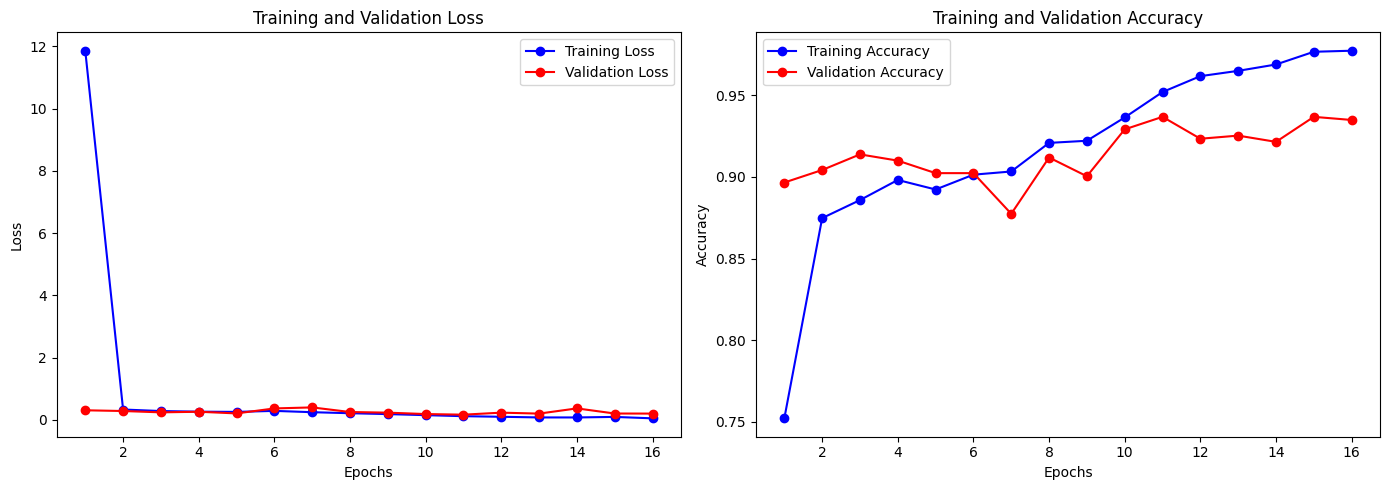


Curvas de treino — Baseline (class weight)
Última train accuracy: 0.9039584398269653
Última val accuracy:   0.8639847040176392
Melhor train accuracy: 0.9046074151992798
Melhor val accuracy:   0.9022988677024841


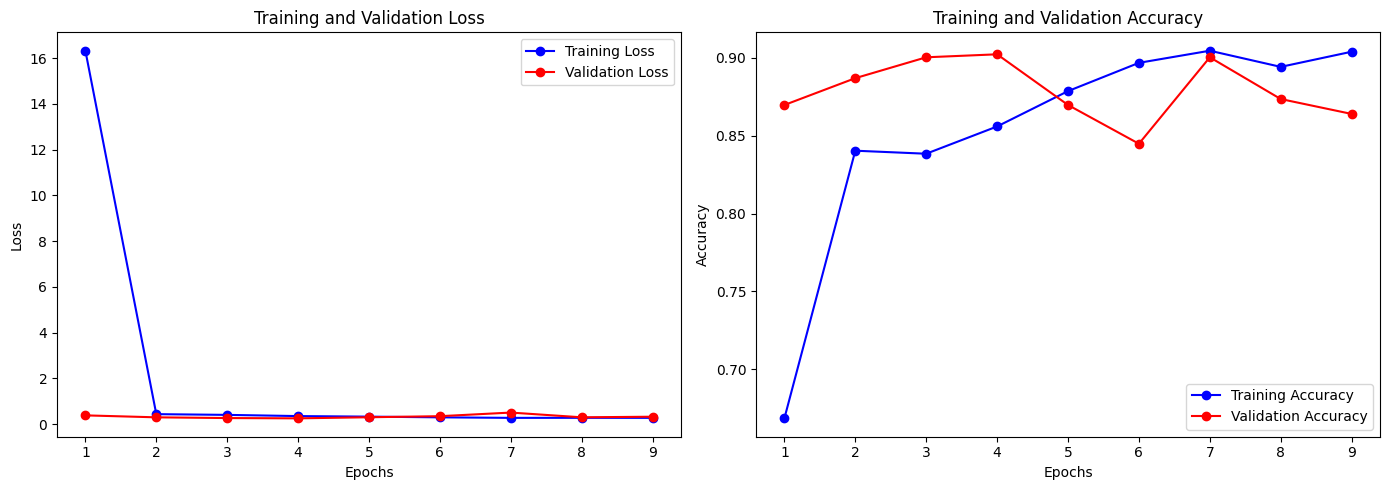


Curvas de treino — Regularizado
Última train accuracy: 0.9597663879394531
Última val accuracy:   0.8524904251098633
Melhor train accuracy: 0.9597663879394531
Melhor val accuracy:   0.9137930870056152


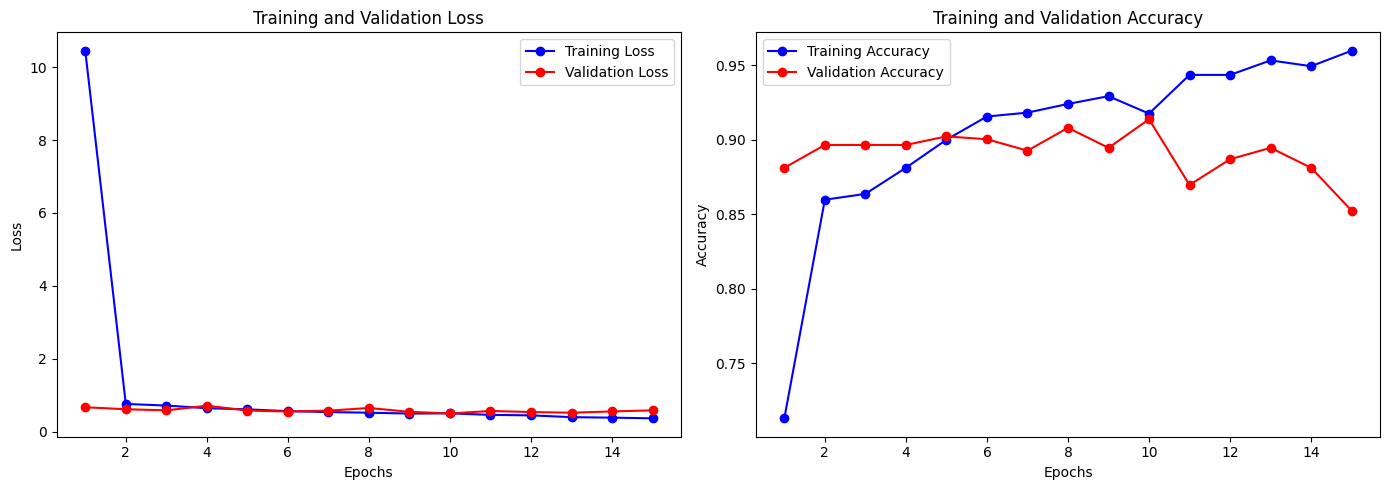


Curvas de treino — EfficientNetB0 (feature extraction)
Última train accuracy: 0.944192111492157
Última val accuracy:   0.9655172228813171
Melhor train accuracy: 0.9448410272598267
Melhor val accuracy:   0.9655172228813171


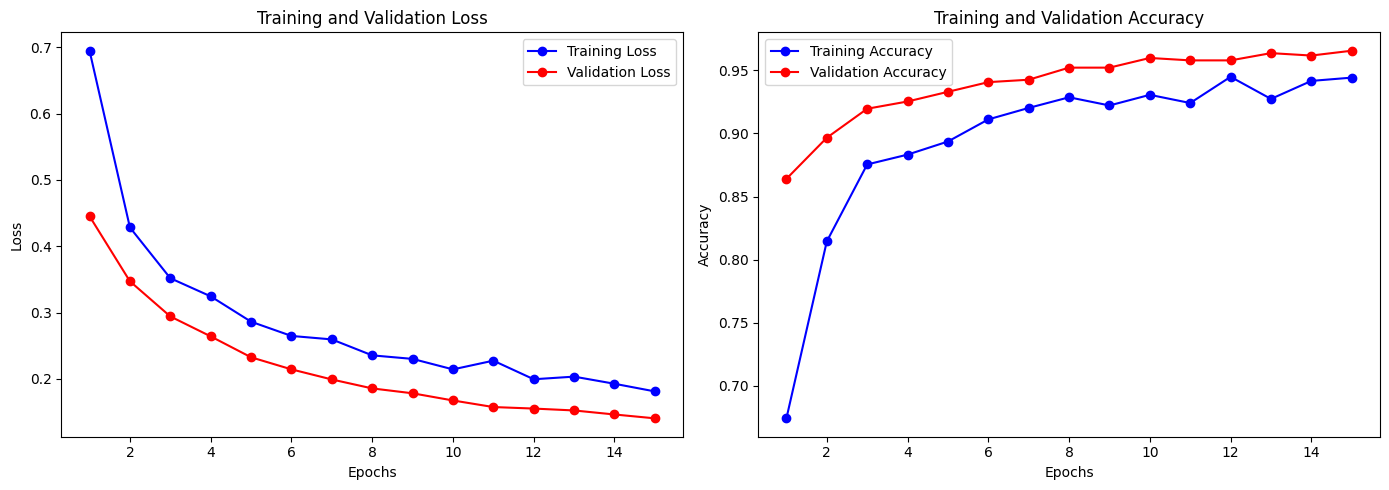


Curvas de treino — EfficientNetB0 (fine-tuned)
Última train accuracy: 0.9987021684646606
Última val accuracy:   0.984674334526062
Melhor train accuracy: 0.9987021684646606
Melhor val accuracy:   0.9865900278091431


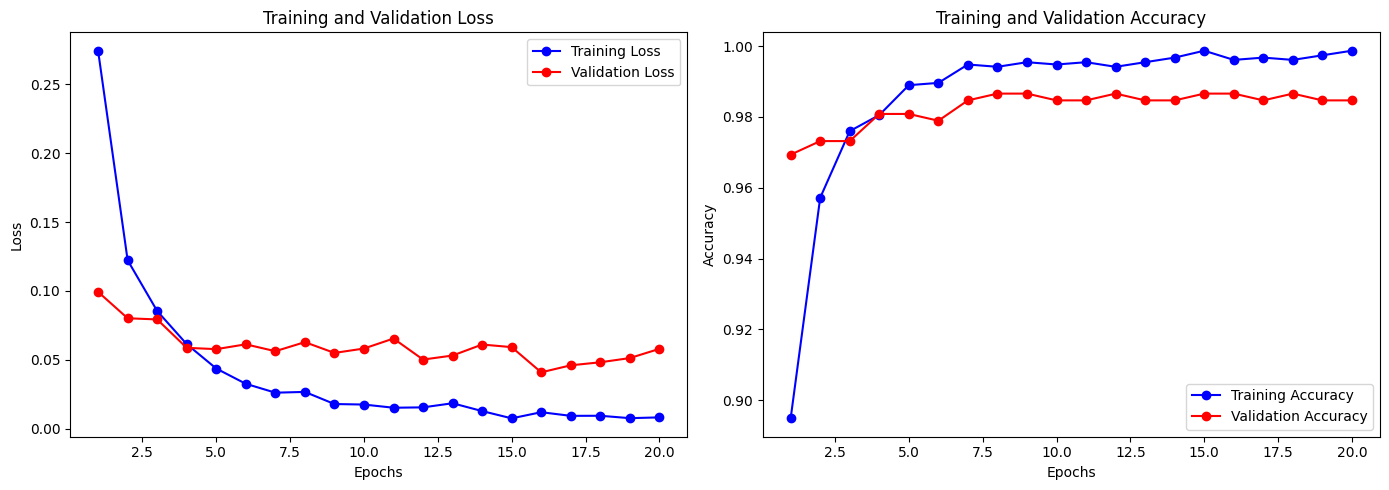


Curvas de treino — ResNet50 (feature extraction)
Última train accuracy: 0.9591174721717834
Última val accuracy:   0.961685836315155
Melhor train accuracy: 0.9591174721717834
Melhor val accuracy:   0.9655172228813171


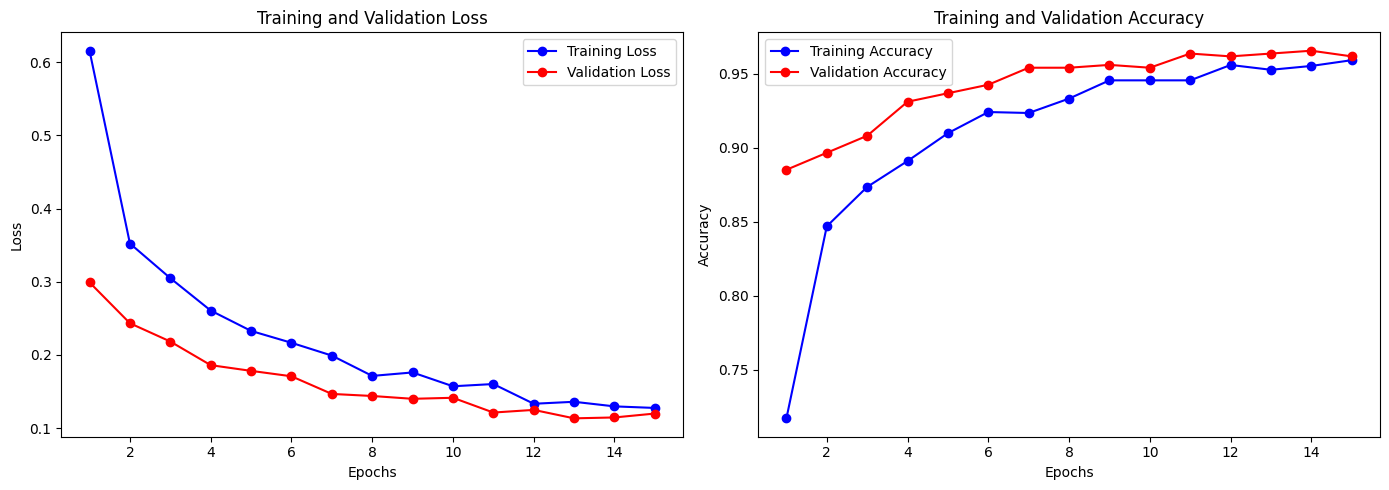


Curvas de treino — ResNet50 (fine-tuned)
Última train accuracy: 1.0
Última val accuracy:   0.9789271950721741
Melhor train accuracy: 1.0
Melhor val accuracy:   0.984674334526062


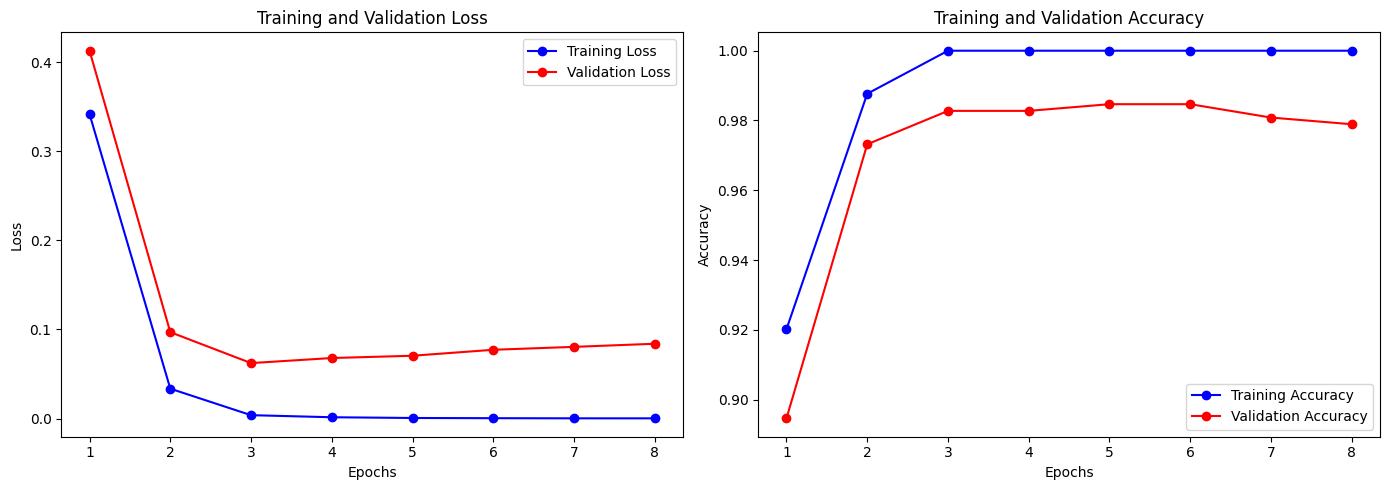

In [38]:
# avaliação de loss function vs accuracy - Curvas de treino (usa o HISTORY)

for nome, modelo, history, X_t, *_ in modelos_treinados:
    print("\n" + "="*55)
    print(f"Curvas de treino — {nome}")
    plot_training_history(history)

## 4.3 Matriz de confusão e classification report
A matriz de confusão permite analisar em detalhe os erros do modelo por classe,
distinguindo entre **Falsos Positivos** (FP) e **Falsos Negativos** (FN).

No contexto do **Use Case 3 — Sistema de Referenciação Hospitalar**, os erros não
têm o mesmo custo clínico:

- **Falso Negativo** (doente com patologia classificado como Normal) — o caso mais
  grave: o doente não é encaminhado e a patologia fica por diagnosticar.
- **Falso Positivo** (exame normal enviado para especialista) — indesejável mas
  menos grave: gera carga desnecessária no sistema, mas sem consequências para o doente.

A análise da matriz de confusão no conjunto de teste — nunca visto durante o treino —
é a avaliação mais honesta da capacidade de generalização do modelo.

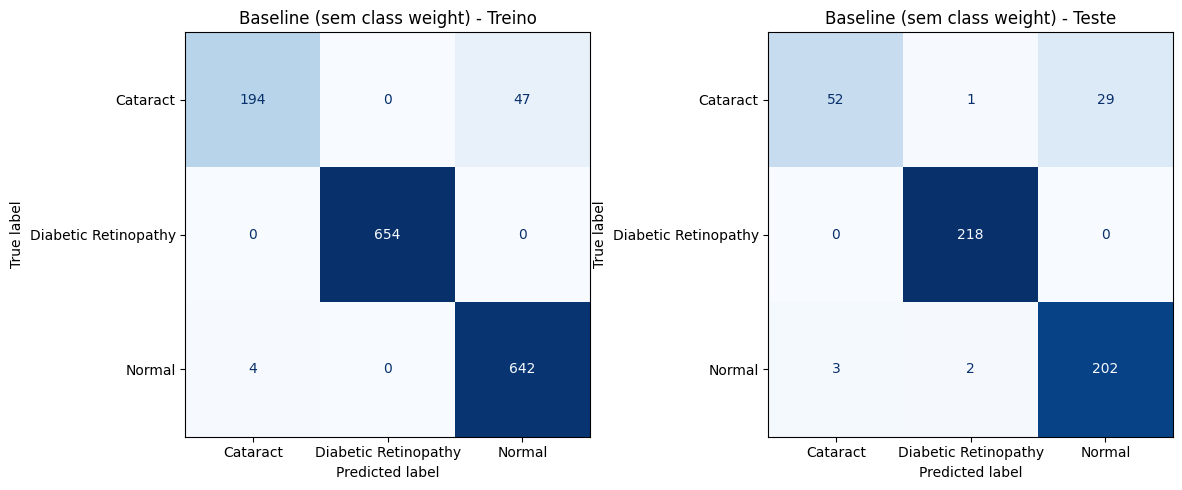

=== Baseline (sem class weight) | TREINO ===
              precision    recall  f1-score   support

           0       0.98      0.80      0.88       241
           1       1.00      1.00      1.00       654
           2       0.93      0.99      0.96       646

    accuracy                           0.97      1541
   macro avg       0.97      0.93      0.95      1541
weighted avg       0.97      0.97      0.97      1541

=== Baseline (sem class weight) | TESTE ===
              precision    recall  f1-score   support

           0       0.95      0.63      0.76        82
           1       0.99      1.00      0.99       218
           2       0.87      0.98      0.92       207

    accuracy                           0.93       507
   macro avg       0.94      0.87      0.89       507
weighted avg       0.93      0.93      0.93       507




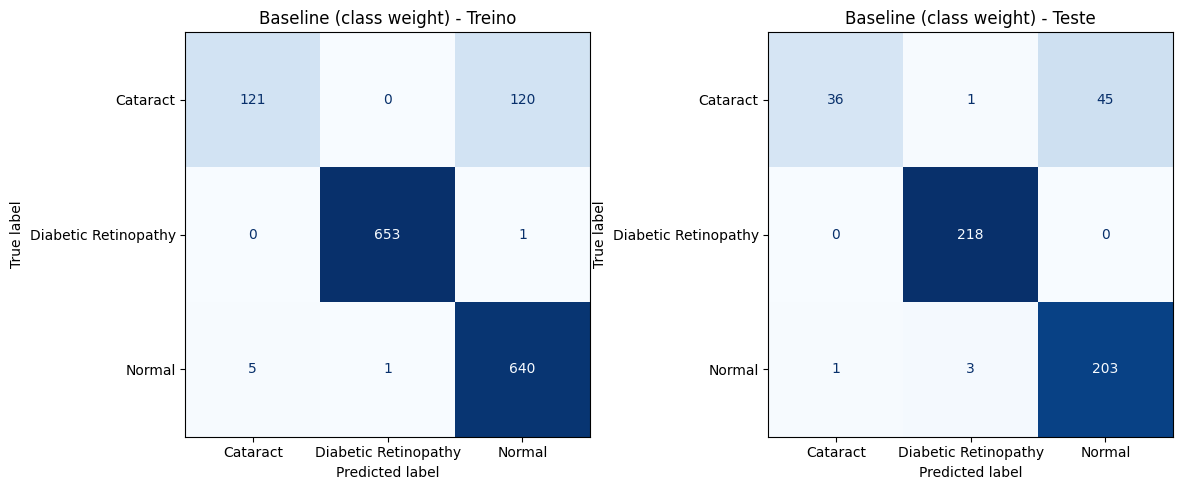

=== Baseline (class weight) | TREINO ===
              precision    recall  f1-score   support

           0       0.96      0.50      0.66       241
           1       1.00      1.00      1.00       654
           2       0.84      0.99      0.91       646

    accuracy                           0.92      1541
   macro avg       0.93      0.83      0.86      1541
weighted avg       0.93      0.92      0.91      1541

=== Baseline (class weight) | TESTE ===
              precision    recall  f1-score   support

           0       0.97      0.44      0.61        82
           1       0.98      1.00      0.99       218
           2       0.82      0.98      0.89       207

    accuracy                           0.90       507
   macro avg       0.92      0.81      0.83       507
weighted avg       0.91      0.90      0.89       507




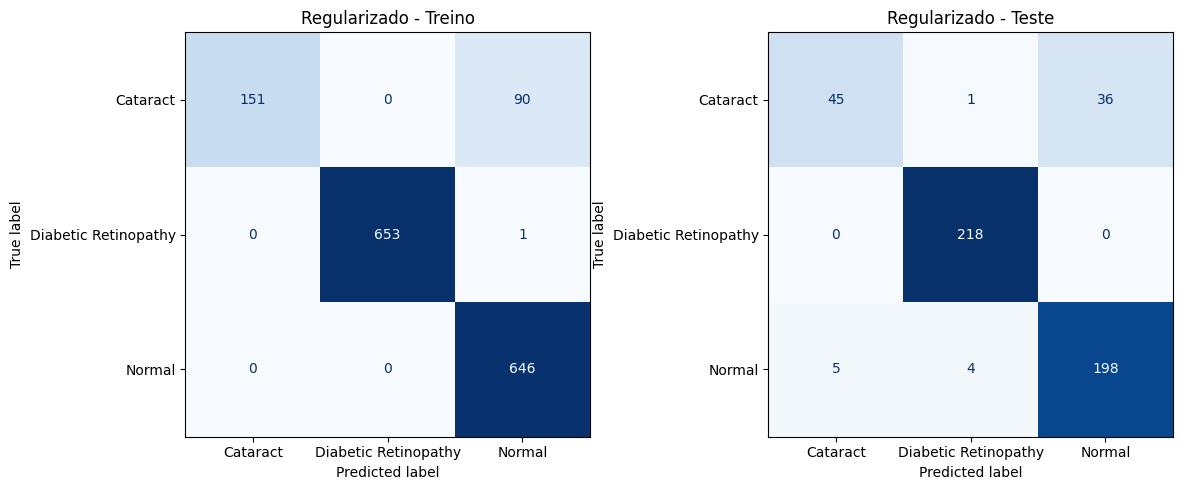

=== Regularizado | TREINO ===
              precision    recall  f1-score   support

           0       1.00      0.63      0.77       241
           1       1.00      1.00      1.00       654
           2       0.88      1.00      0.93       646

    accuracy                           0.94      1541
   macro avg       0.96      0.88      0.90      1541
weighted avg       0.95      0.94      0.94      1541

=== Regularizado | TESTE ===
              precision    recall  f1-score   support

           0       0.90      0.55      0.68        82
           1       0.98      1.00      0.99       218
           2       0.85      0.96      0.90       207

    accuracy                           0.91       507
   macro avg       0.91      0.84      0.86       507
weighted avg       0.91      0.91      0.90       507




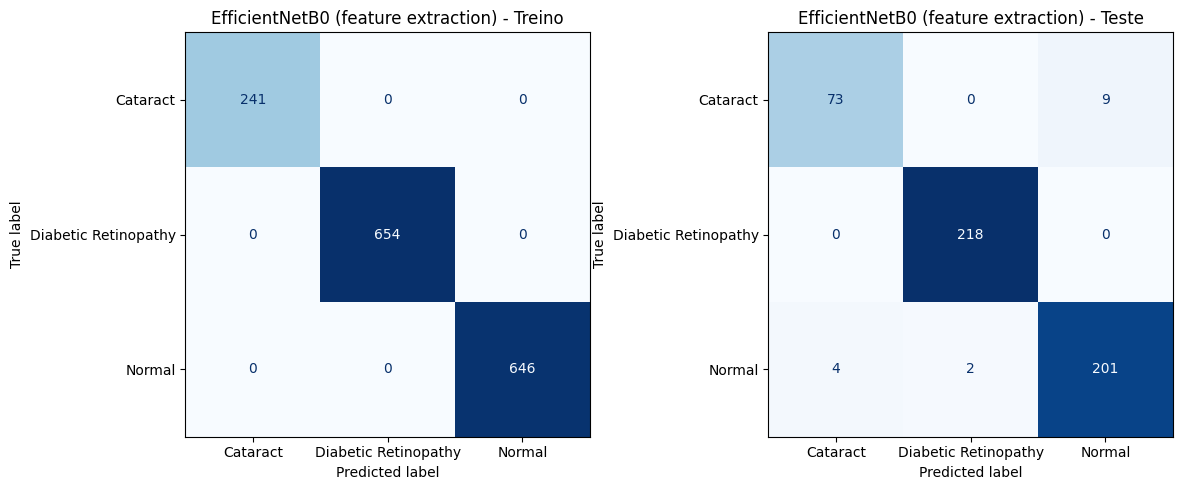

=== EfficientNetB0 (feature extraction) | TREINO ===
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       241
           1       1.00      1.00      1.00       654
           2       1.00      1.00      1.00       646

    accuracy                           1.00      1541
   macro avg       1.00      1.00      1.00      1541
weighted avg       1.00      1.00      1.00      1541

=== EfficientNetB0 (feature extraction) | TESTE ===
              precision    recall  f1-score   support

           0       0.95      0.89      0.92        82
           1       0.99      1.00      1.00       218
           2       0.96      0.97      0.96       207

    accuracy                           0.97       507
   macro avg       0.97      0.95      0.96       507
weighted avg       0.97      0.97      0.97       507




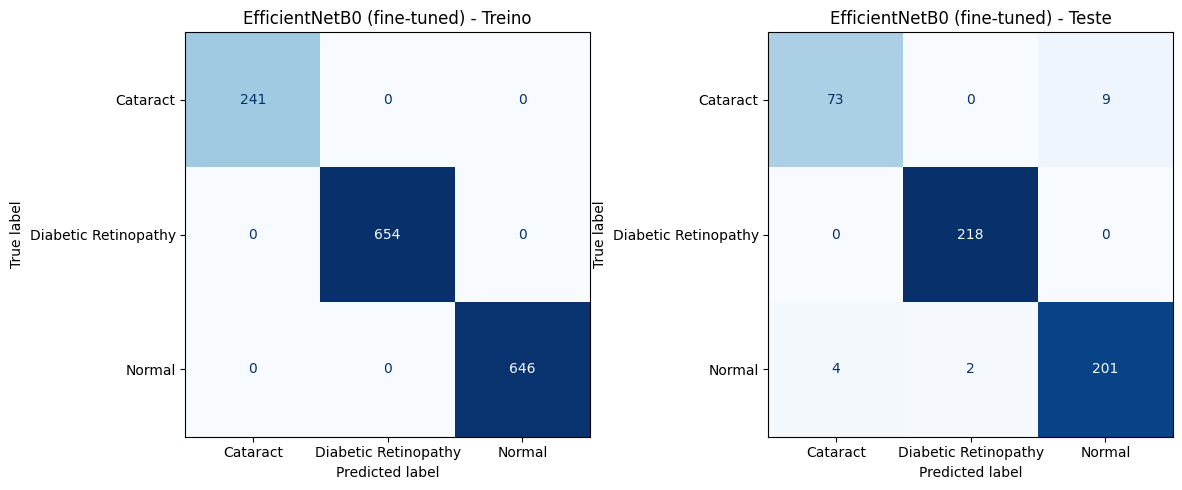

=== EfficientNetB0 (fine-tuned) | TREINO ===
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       241
           1       1.00      1.00      1.00       654
           2       1.00      1.00      1.00       646

    accuracy                           1.00      1541
   macro avg       1.00      1.00      1.00      1541
weighted avg       1.00      1.00      1.00      1541

=== EfficientNetB0 (fine-tuned) | TESTE ===
              precision    recall  f1-score   support

           0       0.95      0.89      0.92        82
           1       0.99      1.00      1.00       218
           2       0.96      0.97      0.96       207

    accuracy                           0.97       507
   macro avg       0.97      0.95      0.96       507
weighted avg       0.97      0.97      0.97       507




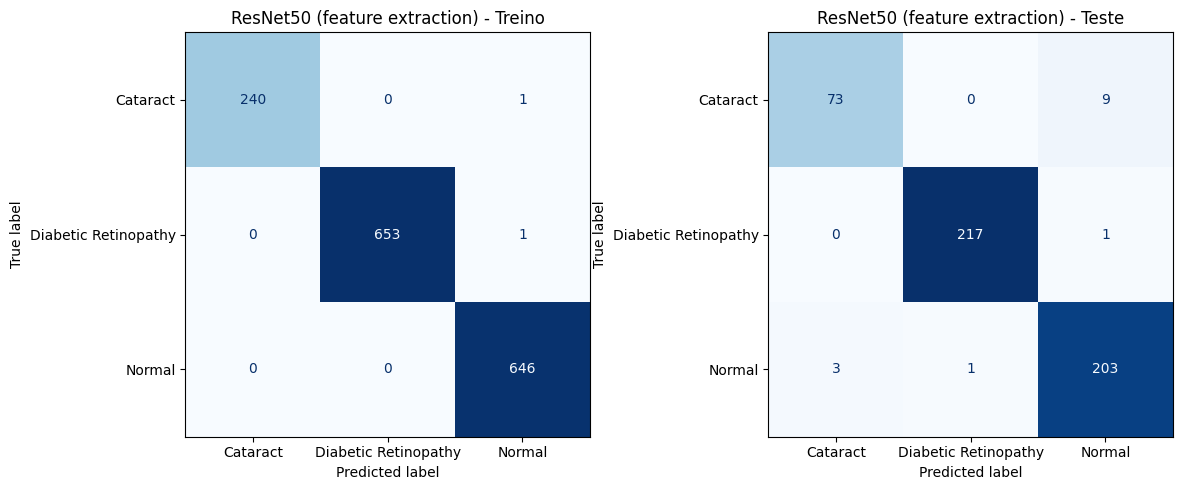

=== ResNet50 (feature extraction) | TREINO ===
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       241
           1       1.00      1.00      1.00       654
           2       1.00      1.00      1.00       646

    accuracy                           1.00      1541
   macro avg       1.00      1.00      1.00      1541
weighted avg       1.00      1.00      1.00      1541

=== ResNet50 (feature extraction) | TESTE ===
              precision    recall  f1-score   support

           0       0.96      0.89      0.92        82
           1       1.00      1.00      1.00       218
           2       0.95      0.98      0.97       207

    accuracy                           0.97       507
   macro avg       0.97      0.96      0.96       507
weighted avg       0.97      0.97      0.97       507




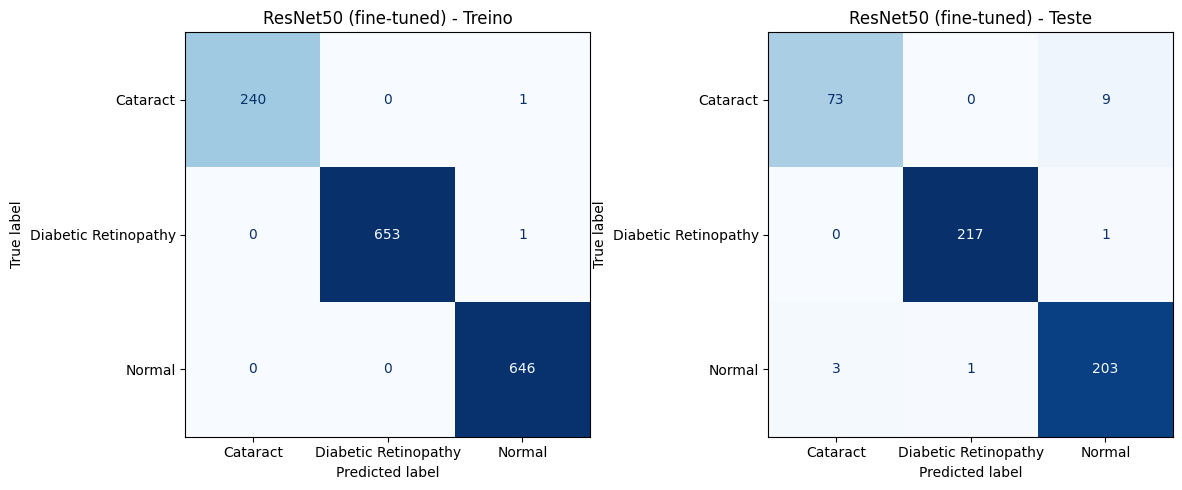

=== ResNet50 (fine-tuned) | TREINO ===
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       241
           1       1.00      1.00      1.00       654
           2       1.00      1.00      1.00       646

    accuracy                           1.00      1541
   macro avg       1.00      1.00      1.00      1541
weighted avg       1.00      1.00      1.00      1541

=== ResNet50 (fine-tuned) | TESTE ===
              precision    recall  f1-score   support

           0       0.96      0.89      0.92        82
           1       1.00      1.00      1.00       218
           2       0.95      0.98      0.97       207

    accuracy                           0.97       507
   macro avg       0.97      0.96      0.96       507
weighted avg       0.97      0.97      0.97       507



In [39]:
# Matrizes de confusão + classification report (usa o MODELO)
for nome, modelo, history, X_t, X_tr, y_tr in modelos_treinados:
    print("\n" + "="*55)
    avaliar_modelo_multiclasse(modelo, X_tr, y_tr, X_t, y_test, nome_modelo=nome)

## 4.4 ROC
### Curva ROC (Receiver Operating Characteristic)
A curva ROC representa a relação entre a **Sensibilidade** (Taxa de Verdadeiros Positivos)
e **1 - Especificidade** (Taxa de Falsos Positivos) para diferentes thresholds de decisão.
O valor de **AUC-ROC** (Área Sob a Curva) sintetiza o desempenho global do modelo —
um valor de 1.0 representa classificação perfeita e 0.5 equivale a uma decisão aleatória.

### Curva Precision-Recall
A curva Precision-Recall é particularmente relevante em datasets desbalanceados como
o nosso, onde a classe *cataract* representa a minoria. Ao contrário da curva ROC,
não é influenciada pelo elevado número de verdadeiros negativos, sendo uma avaliação
mais honesta do desempenho nas classes minoritárias.

O valor de **Average Precision (AP)** resume a curva — quanto mais próximo de 1.0,
melhor o modelo deteta a classe em questão independentemente do threshold escolhido.

No contexto do **Use Case 3**, um AUC-ROC elevado na classe *cataract* é crítico:
garante que o modelo consegue separar doentes com catarata de casos normais,
reduzindo o risco de falsos negativos no encaminhamento hospitalar.


ROC e Precision-Recall — Baseline (sem class weight)


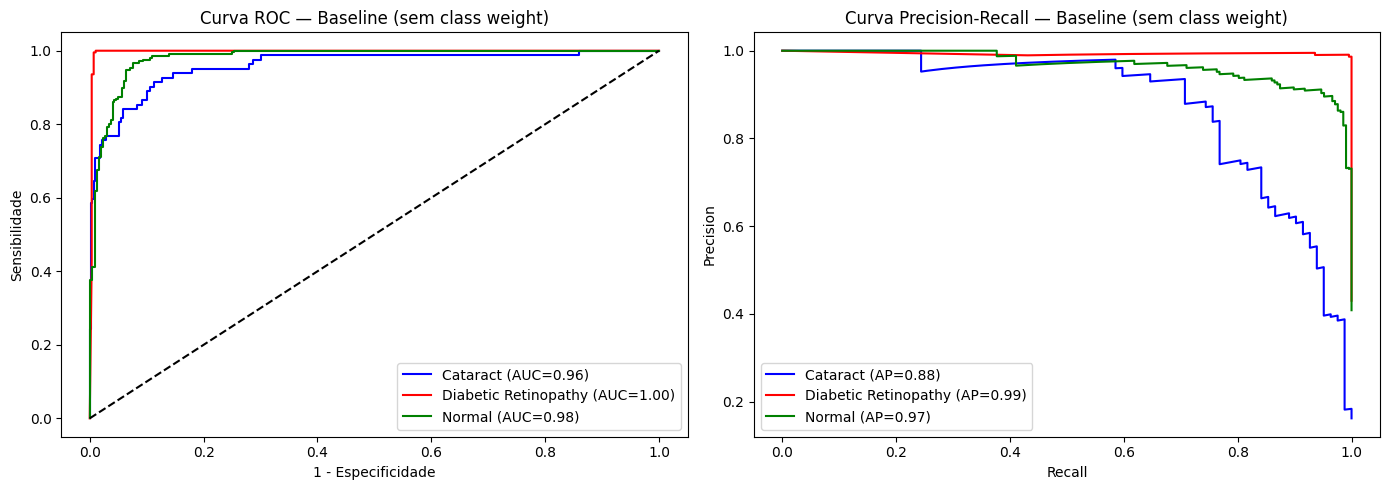


ROC e Precision-Recall — Baseline (class weight)


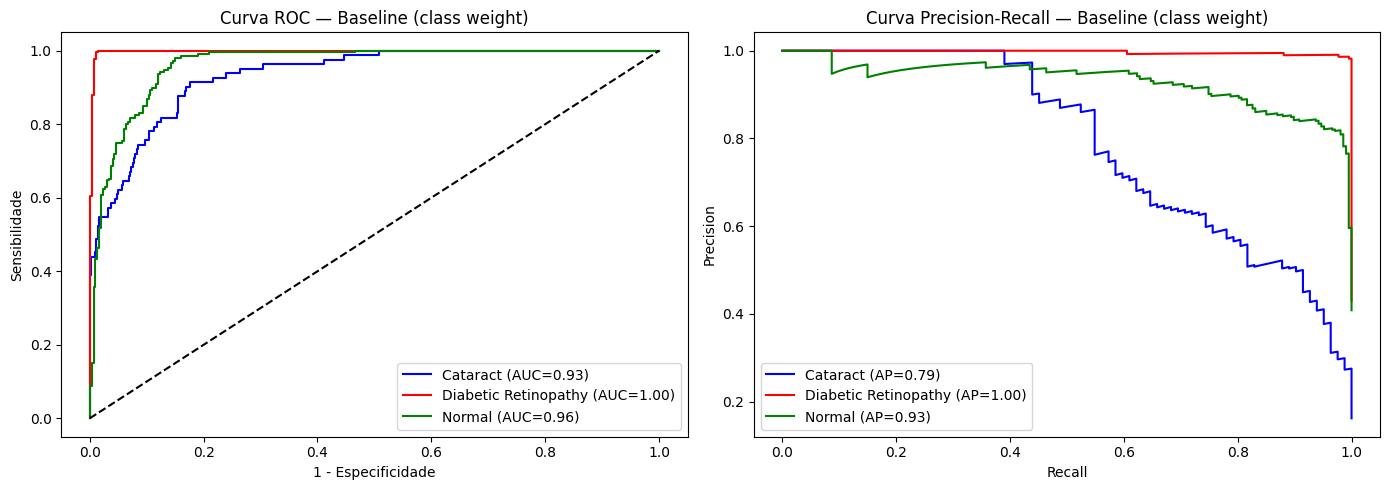


ROC e Precision-Recall — Regularizado


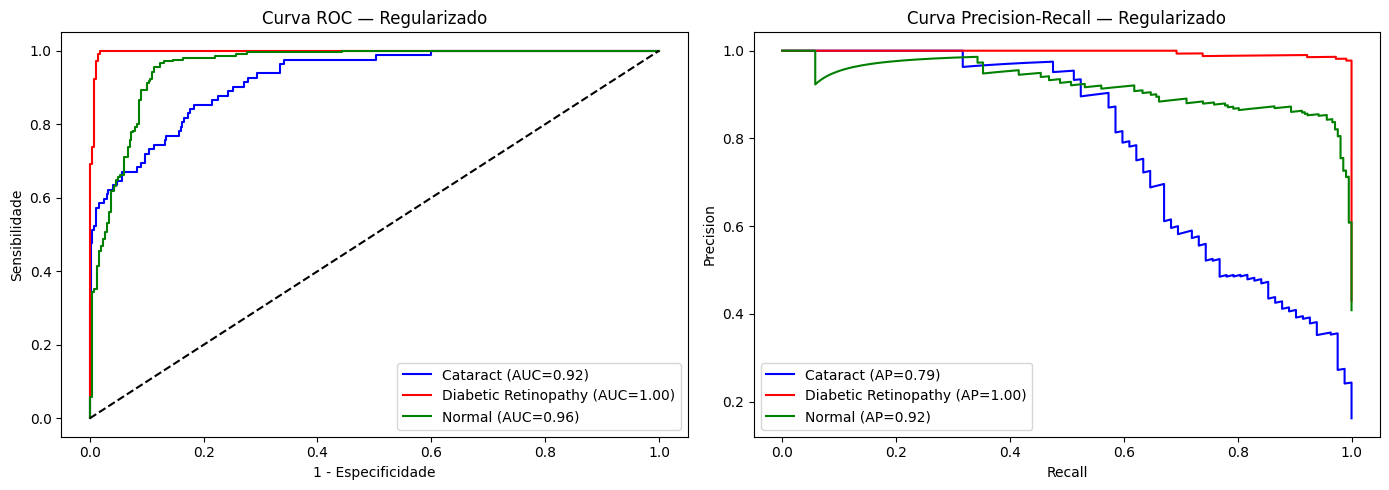


ROC e Precision-Recall — EfficientNetB0 (feature extraction)


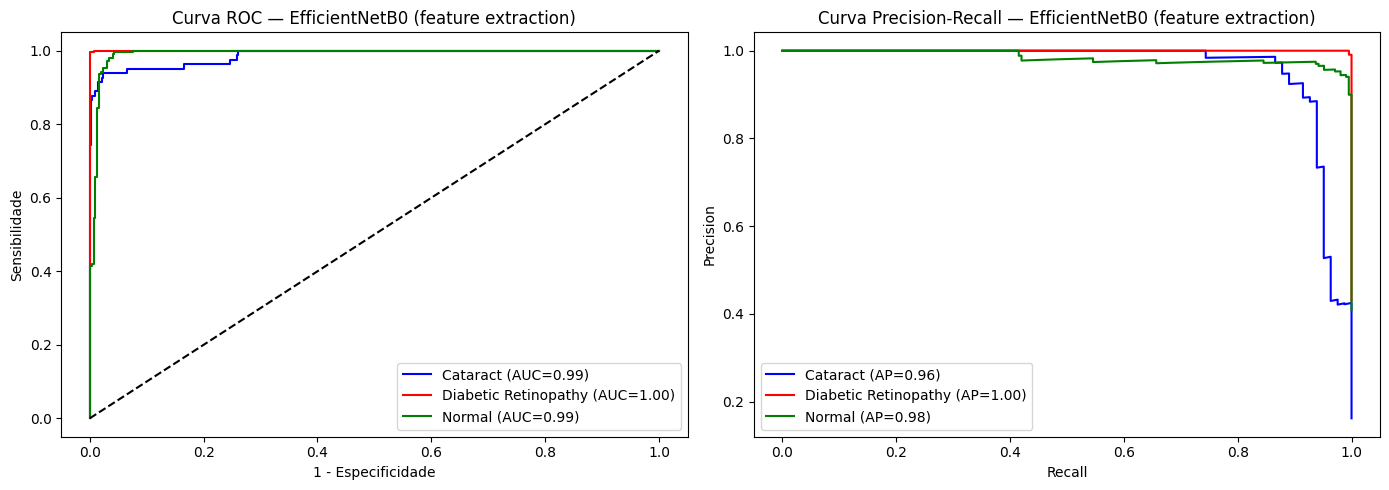


ROC e Precision-Recall — EfficientNetB0 (fine-tuned)


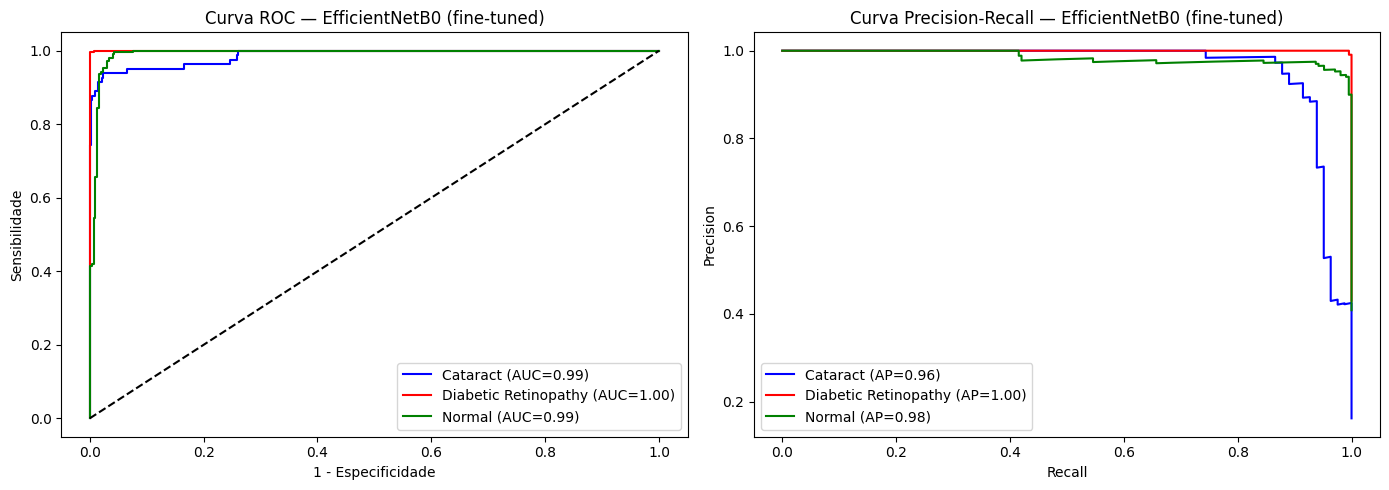


ROC e Precision-Recall — ResNet50 (feature extraction)


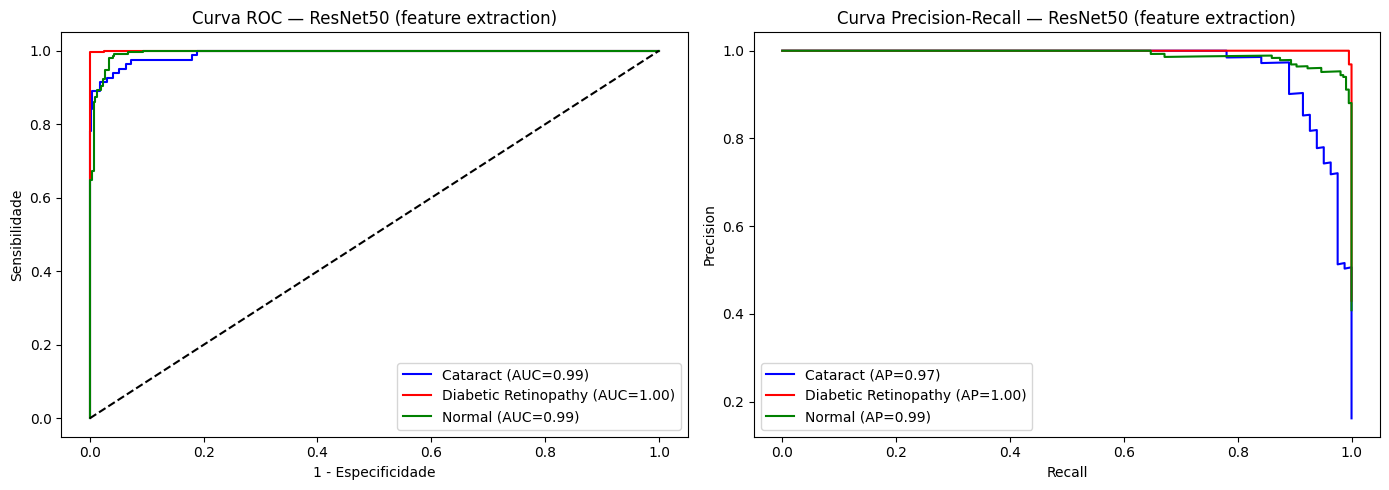


ROC e Precision-Recall — ResNet50 (fine-tuned)


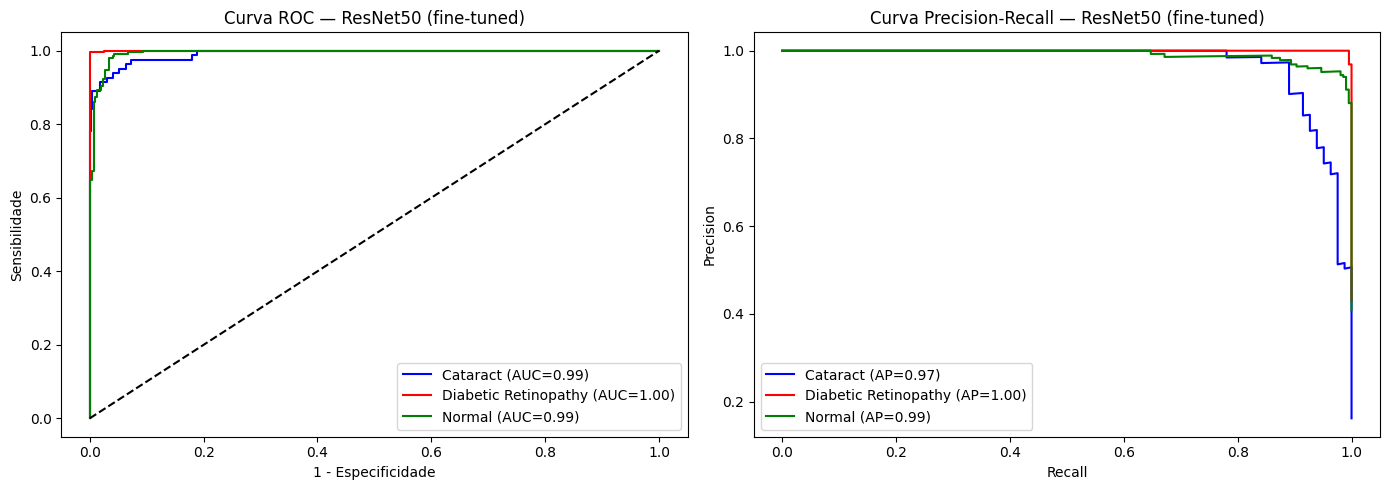

In [40]:
# ROC + Precision-Recall

for nome, modelo, history, X_t, *_ in modelos_treinados:
    print("\n" + "="*55)
    print(f"ROC e Precision-Recall — {nome}")
    plot_roc_pr_curves(modelo, X_t, y_test, class_names, nome)

## 4.5 Sensibilidade vs Especificidade por Threshold

A curva de Sensibilidade vs Especificidade por threshold permite analisar o impacto
da escolha do threshold de decisão no desempenho do modelo para cada classe.

- **Sensibilidade (Recall)** — proporção de casos positivos corretamente identificados.
  No UC3, uma sensibilidade elevada nas classes patológicas garante que doentes com
  catarata ou retinopatia diabética não são incorretamente classificados como normais.
- **Especificidade** — proporção de casos negativos corretamente identificados.
  Uma especificidade elevada reduz o número de exames normais enviados desnecessariamente
  para avaliação especializada.

O threshold padrão de 0.5 nem sempre é o mais adequado num contexto clínico. A análise
desta curva permite identificar o ponto de equilíbrio entre sensibilidade e especificidade
para cada classe, informando uma possível calibração do sistema para o contexto hospitalar.


Sensibilidade vs Especificidade — Baseline (sem class weight)


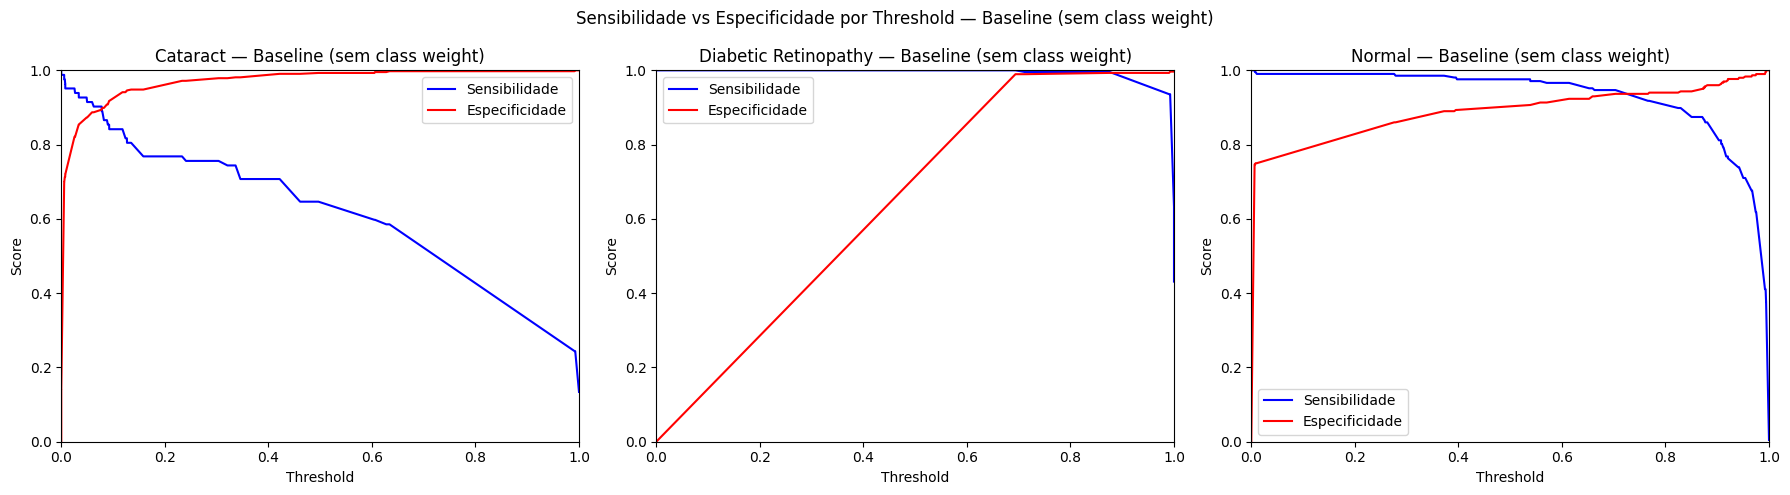


Sensibilidade vs Especificidade — Baseline (class weight)


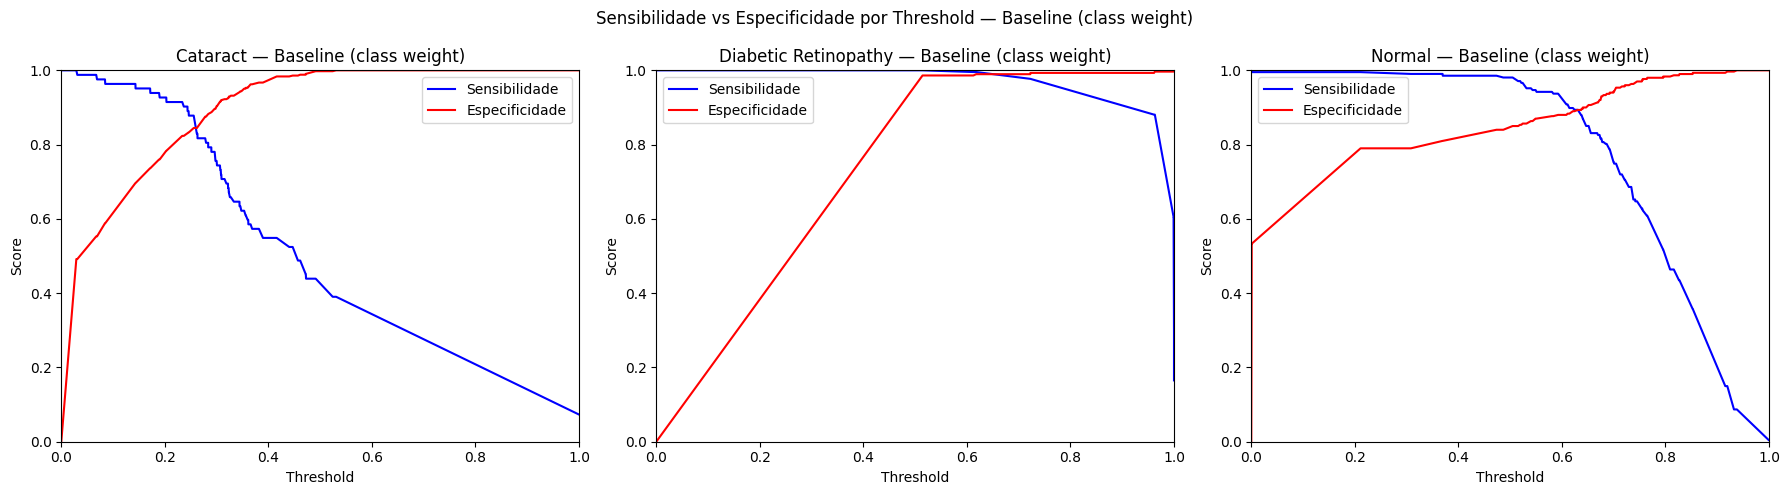


Sensibilidade vs Especificidade — Regularizado


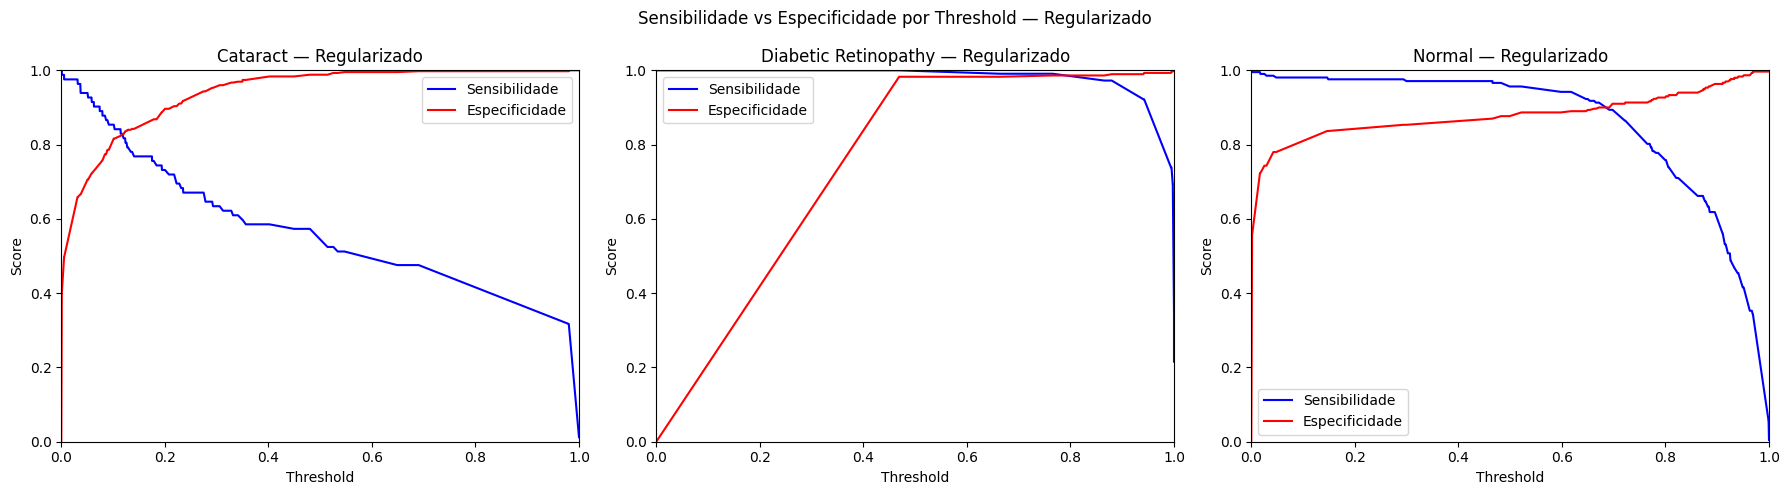


Sensibilidade vs Especificidade — EfficientNetB0 (feature extraction)


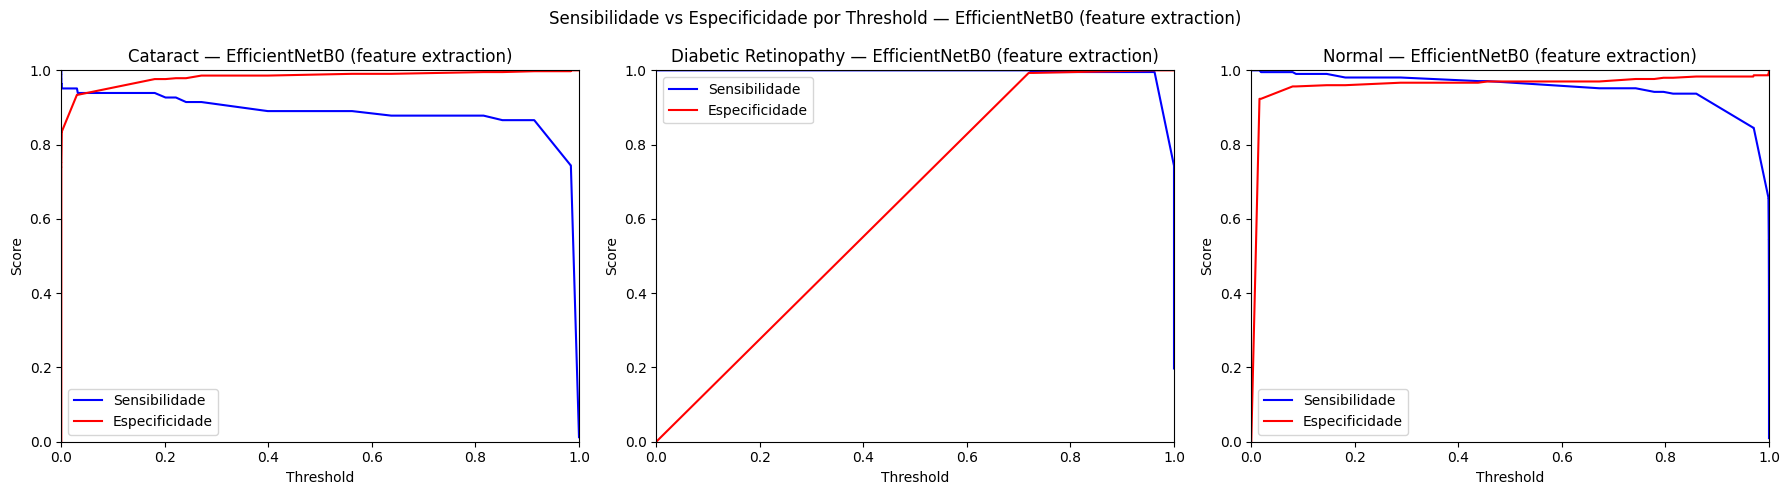


Sensibilidade vs Especificidade — EfficientNetB0 (fine-tuned)


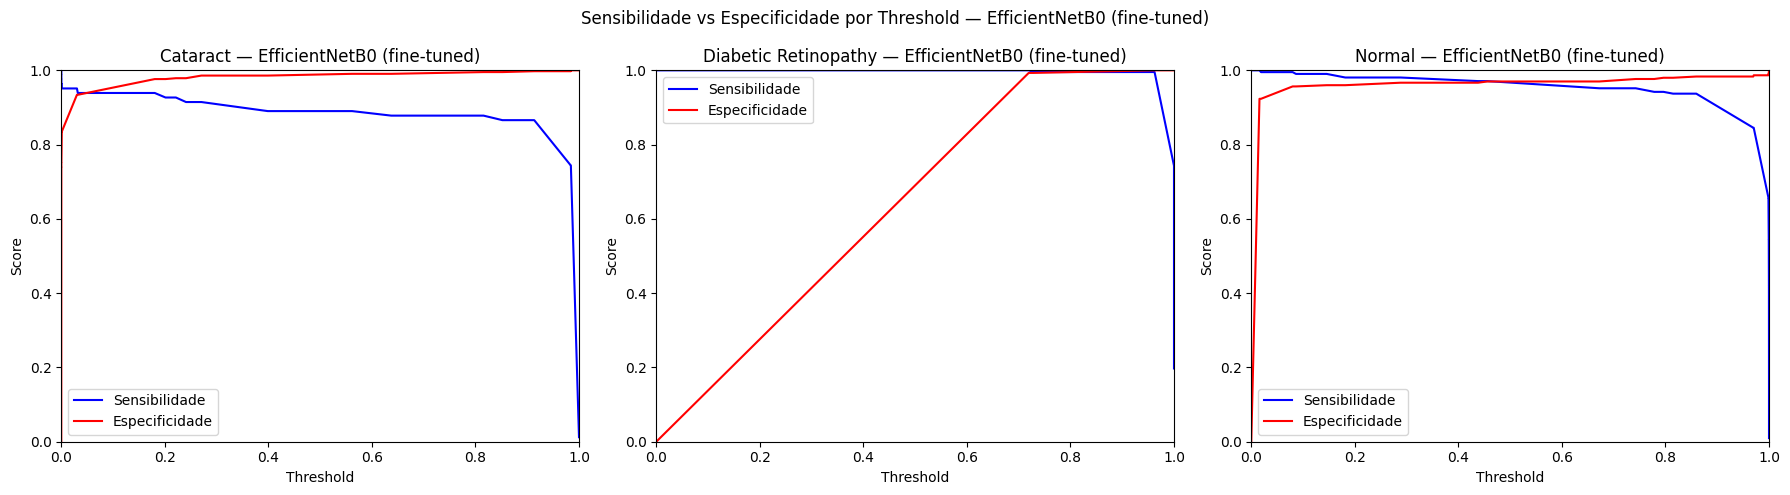


Sensibilidade vs Especificidade — ResNet50 (feature extraction)


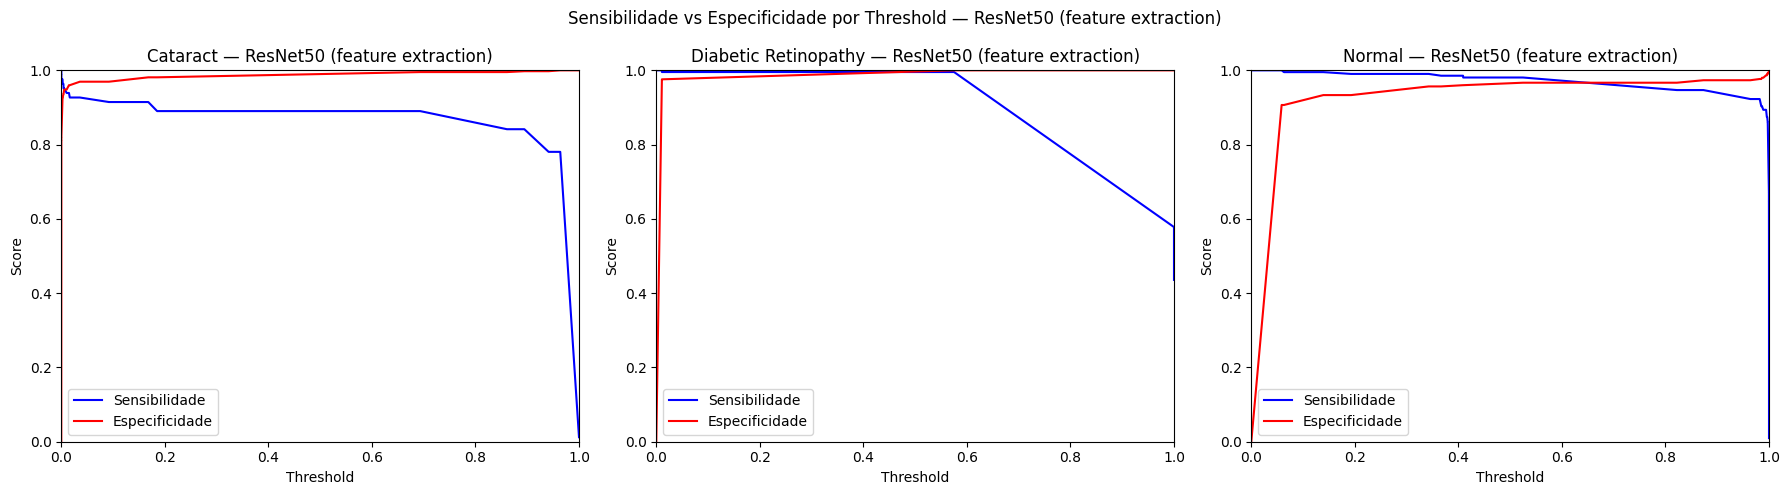


Sensibilidade vs Especificidade — ResNet50 (fine-tuned)


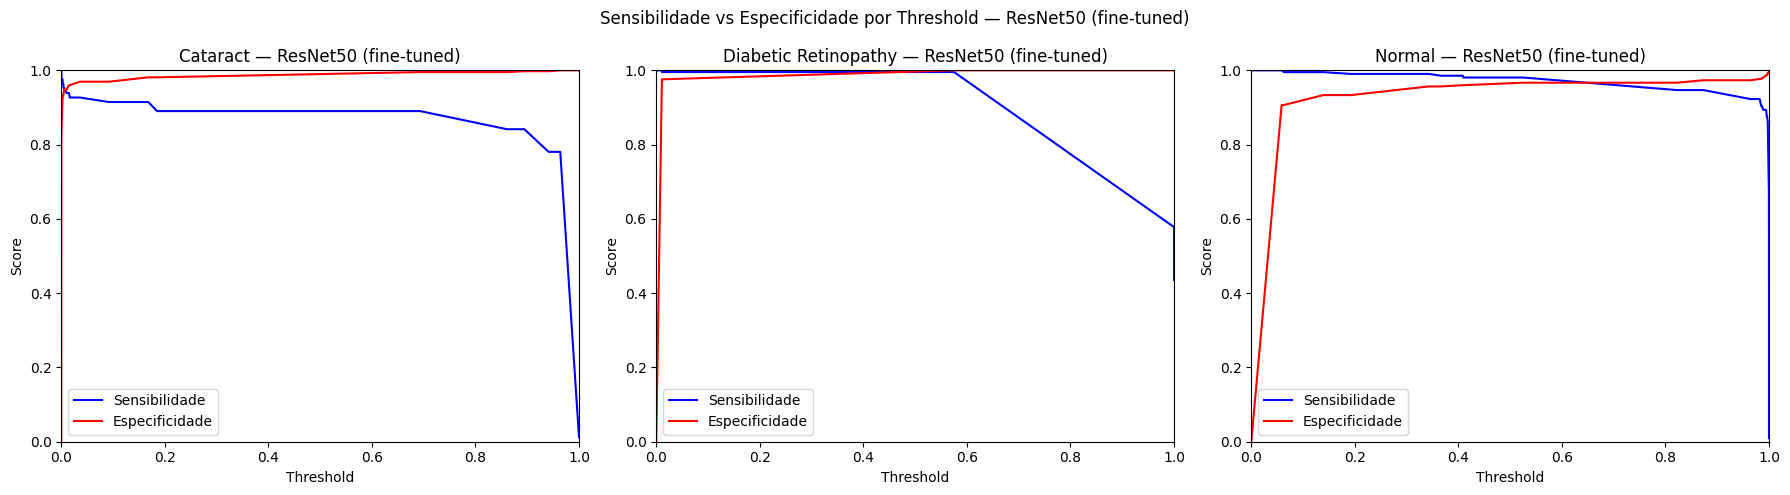

In [41]:
# Sensibilidade vs Especificidade por Threshold

for nome, modelo, history, X_t, *_ in modelos_treinados:
    print("\n" + "="*55)
    print(f"Sensibilidade vs Especificidade — {nome}")
    plot_sensitivity_specificity_threshold(modelo, X_t, y_test, class_names, nome)

In [42]:
def tabela_comparativa(modelos_treinados, y_test, class_names):
    """
    Gera uma tabela comparativa de todos os modelos treinados.
    Métricas calculadas no conjunto de teste:
    Accuracy, F1-macro, AUC-ROC macro, Recall por classe.
    """
    rows = []
    for nome, modelo, history, X_t, X_tr, y_tr in modelos_treinados:

        # previsões e binarização para métricas multiclasse
        y_pred_probs = modelo.predict(X_t, verbose=0)
        y_pred       = np.argmax(y_pred_probs, axis=1)
        y_bin        = label_binarize(y_test, classes=[0, 1, 2])

        # calcular métricas
        acc     = accuracy_score(y_test, y_pred)
        f1      = f1_score(y_test, y_pred, average="macro")
        auc     = roc_auc_score(y_bin, y_pred_probs, average="macro", multi_class="ovr")
        recalls = recall_score(y_test, y_pred, average=None)  # recall por classe

        rows.append({
            "Modelo":          nome,
            "Accuracy":        f"{acc:.4f}",
            "F1-macro":        f"{f1:.4f}",
            "AUC-ROC macro":   f"{auc:.4f}",
            "Recall Cataract": f"{recalls[0]:.4f}",
            "Recall Diabetic": f"{recalls[1]:.4f}",
            "Recall Normal":   f"{recalls[2]:.4f}",
        })

    df = pd.DataFrame(rows).set_index("Modelo")
    print(df.to_string())
    return df

## 4.6 Tabela Comparativa de Modelos

In [43]:
df_resultados = tabela_comparativa(modelos_treinados, y_test, class_names)

                                    Accuracy F1-macro AUC-ROC macro Recall Cataract Recall Diabetic Recall Normal
Modelo                                                                                                           
Baseline (sem class weight)           0.9310   0.8916        0.9788          0.6341          1.0000        0.9758
Baseline (class weight)               0.9014   0.8294        0.9644          0.4390          1.0000        0.9807
Regularizado                          0.9093   0.8561        0.9592          0.5488          1.0000        0.9565
EfficientNetB0 (feature extraction)   0.9704   0.9592        0.9928          0.8902          1.0000        0.9710
EfficientNetB0 (fine-tuned)           0.9704   0.9592        0.9928          0.8902          1.0000        0.9710
ResNet50 (feature extraction)         0.9724   0.9620        0.9954          0.8902          0.9954        0.9807
ResNet50 (fine-tuned)                 0.9724   0.9620        0.9954          0.8902     

## 5. Explicabilidade Visual (Grad-CAM)

Num contexto clínico de referenciação hospitalar (Use Case 3), a interpretabilidade do modelo é um fator crítico de sucesso. O Grad-CAM (Gradient-weighted Class Activation Mapping) permite-nos visualizar em que regiões espaciais da imagem oftalmológica a Convolutional Neural Network (CNN) se focou para tomar a sua decisão.

Esta análise permite-nos validar se o modelo está a aprender a identificar características patológicas reais (como exsudatos duros na retinopatia diabética ou opacidade na lente na catarata) em vez de focar em ruído ou em artefactos irrelevantes presentes nas imagens.

In [44]:
def show_grad_cam(model, image, class_names, last_conv_layer_name, base_model=None):
    """
    Gera e visualiza o Grad-CAM para um modelo Sequential (CNNs) ou Functional (TL).
    - base_model=None  → modo Sequential (CNN treinada de raiz)
    - base_model=<obj> → modo Functional (EfficientNet, ResNet)
    """
    img_array = np.expand_dims(image.astype("float32"), axis=0)

    if base_model is None:
        # Dividir o modelo em duas partes: até à última conv e o classificador
        last_conv_layer = model.get_layer(last_conv_layer_name)
        last_conv_index = model.layers.index(last_conv_layer)
        conv_model  = tf.keras.Sequential(model.layers[:last_conv_index + 1])
        head_layers = model.layers[last_conv_index + 1:]

        with tf.GradientTape() as tape:
            conv_outputs = conv_model(img_array)
            tape.watch(conv_outputs)  # gravar gradientes sobre os outputs da conv
            x = conv_outputs
            for layer in head_layers:
                x = layer(x, training=False)
            predictions = x
            pred_index  = tf.argmax(predictions[0])  # classe prevista
            loss        = predictions[:, pred_index]
    else:
        # Localizar a camada de pré-processamento (Lambda) se existir
        lambda_layers    = [l for l in model.layers if isinstance(l, tf.keras.layers.Lambda)]
        preprocess_layer = lambda_layers[0] if lambda_layers else None

        # Extractor que devolve: activações da última conv + output da base
        feat_extractor = tf.keras.Model(
            inputs=base_model.inputs,
            outputs=[base_model.get_layer(last_conv_layer_name).output, base_model.output]
        )
        # Camadas do classificador (após a base pré-treinada)
        base_idx    = next(i for i, l in enumerate(model.layers) if l.name == base_model.name)
        head_layers = model.layers[base_idx + 1:]

        with tf.GradientTape() as tape:
            preprocessed           = preprocess_layer(img_array) if preprocess_layer else img_array
            conv_outputs, base_out = feat_extractor(preprocessed)
            tape.watch(conv_outputs)
            x = base_out
            for layer in head_layers:
                x = layer(x, training=False)
            predictions = x
            pred_index  = tf.argmax(predictions[0])
            loss        = predictions[:, pred_index]

    # --- Cálculo do heatmap ---
    grads        = tape.gradient(loss, conv_outputs)         # gradientes da loss sobre a conv
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))     # média espacial dos gradientes
    heatmap      = conv_outputs[0] @ pooled_grads[..., tf.newaxis]  # ponderação dos mapas
    heatmap      = tf.squeeze(heatmap)
    heatmap      = tf.maximum(heatmap, 0)                    # ReLU — só activações positivas
    if tf.reduce_max(heatmap) > 0:
        heatmap = heatmap / tf.reduce_max(heatmap)           # normalização [0, 1]
    heatmap = tf.image.resize(
        heatmap[..., tf.newaxis], (image.shape[0], image.shape[1])
    ).numpy().squeeze()                                       # upsample para dimensão da imagem

    # --- Visualização ---
    preds           = model.predict(img_array, verbose=0)
    final_pred_idx  = np.argmax(preds[0])
    final_pred_prob = preds[0][final_pred_idx]

    plt.figure(figsize=(12, 4))
    img_disp = image.astype("uint8") if np.max(image) > 1 else image
    plt.subplot(1, 3, 1); plt.imshow(img_disp); plt.title("Imagem Original"); plt.axis("off")
    plt.subplot(1, 3, 2); plt.imshow(heatmap, cmap="jet"); plt.title("Grad-CAM"); plt.axis("off")
    plt.subplot(1, 3, 3); plt.imshow(img_disp)
    plt.imshow(heatmap, cmap="jet", alpha=0.4)
    plt.title(f"Overlay | {class_names[final_pred_idx]}: {final_pred_prob:.2f}"); plt.axis("off")
    plt.tight_layout()
    plt.show()

Regularizado — Cataract


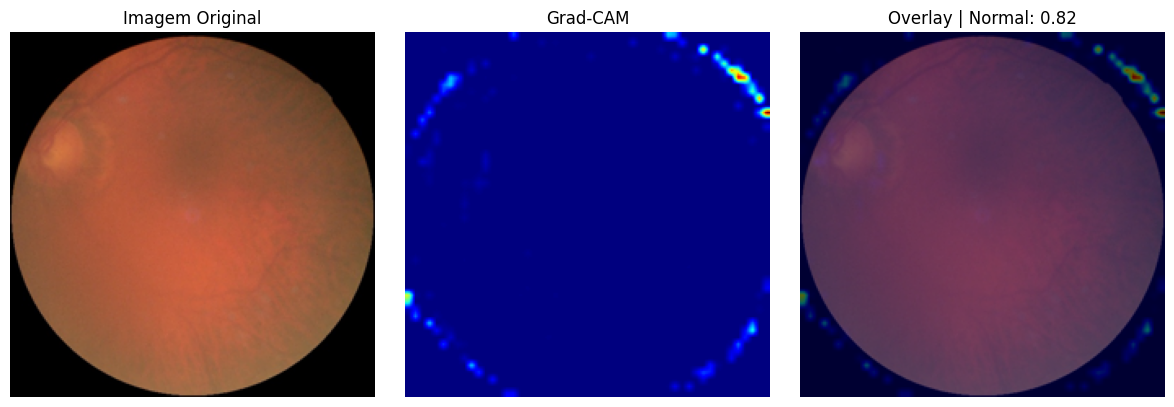

Regularizado — Diabetic


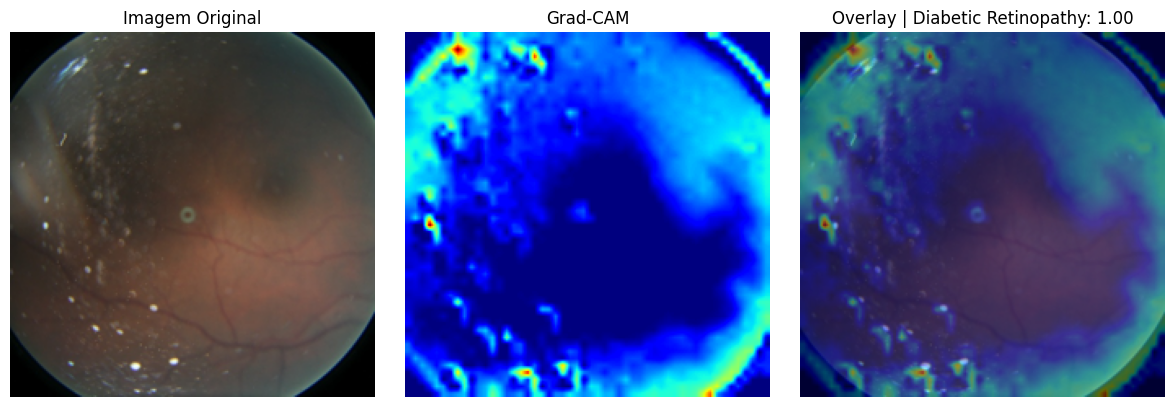

Regularizado — Normal


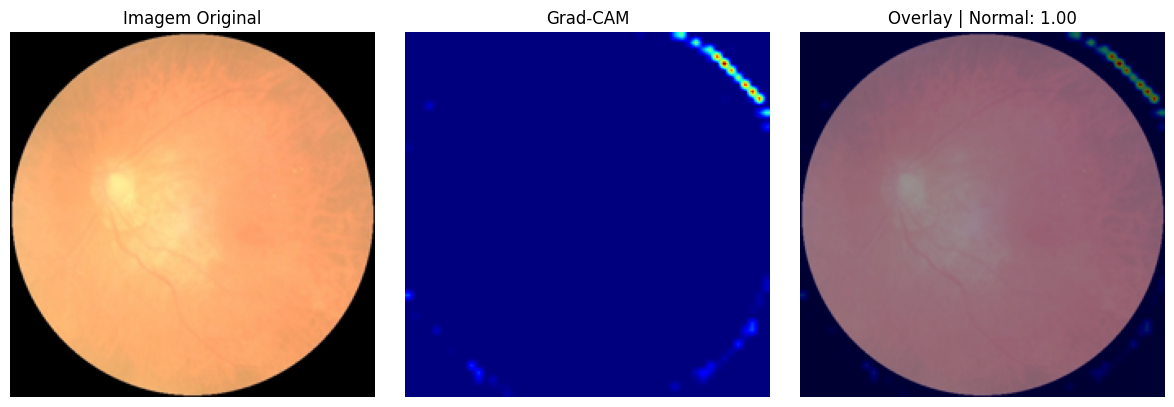

EfficientNetB0 — Cataract


/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


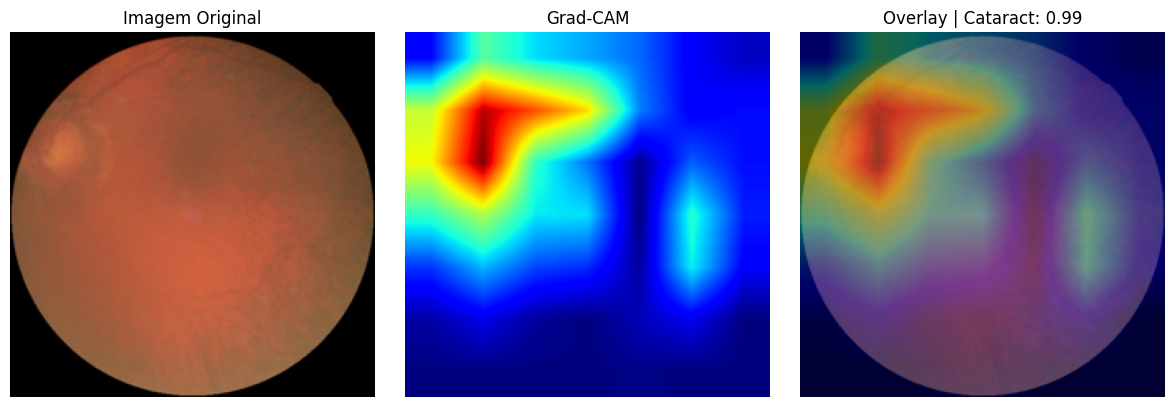

EfficientNetB0 — Diabetic


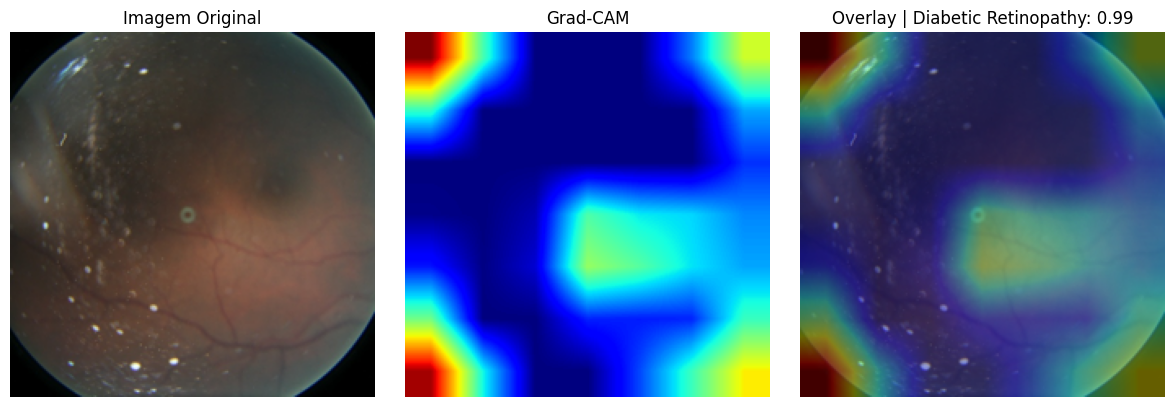

EfficientNetB0 — Normal


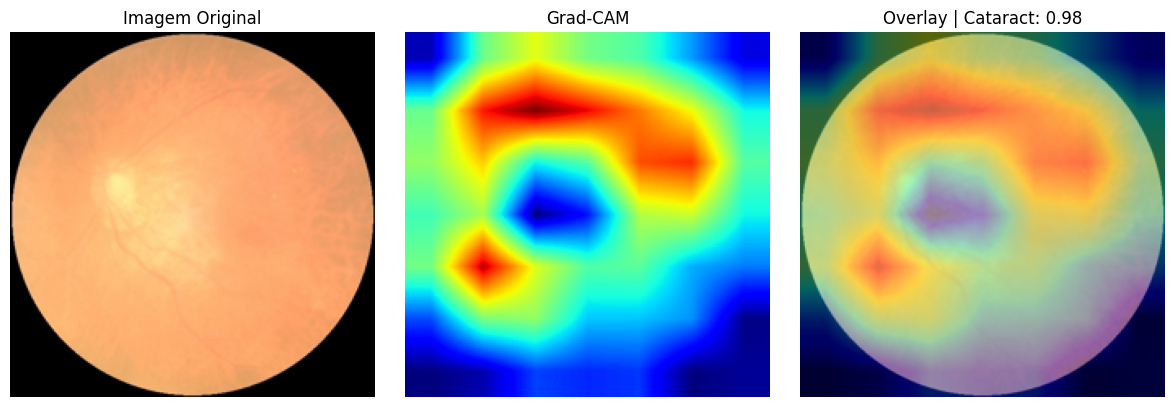

ResNet50 — Cataract


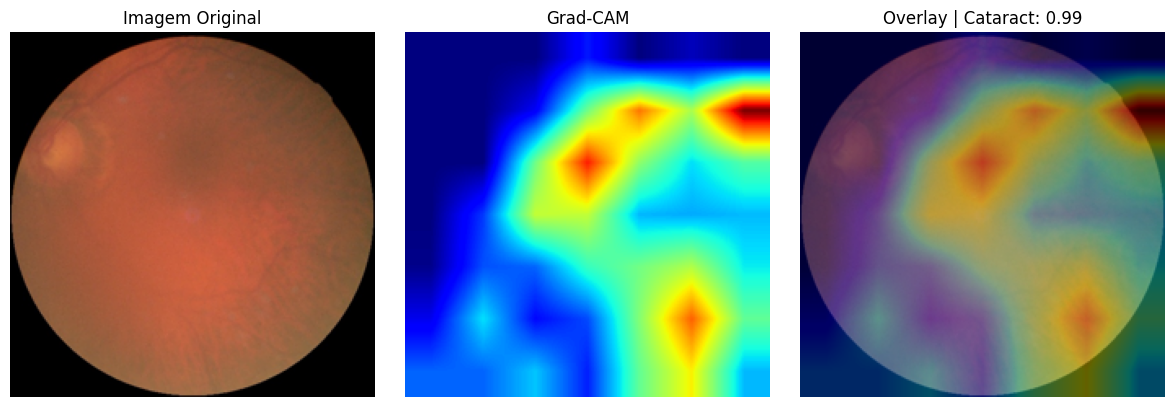

ResNet50 — Diabetic


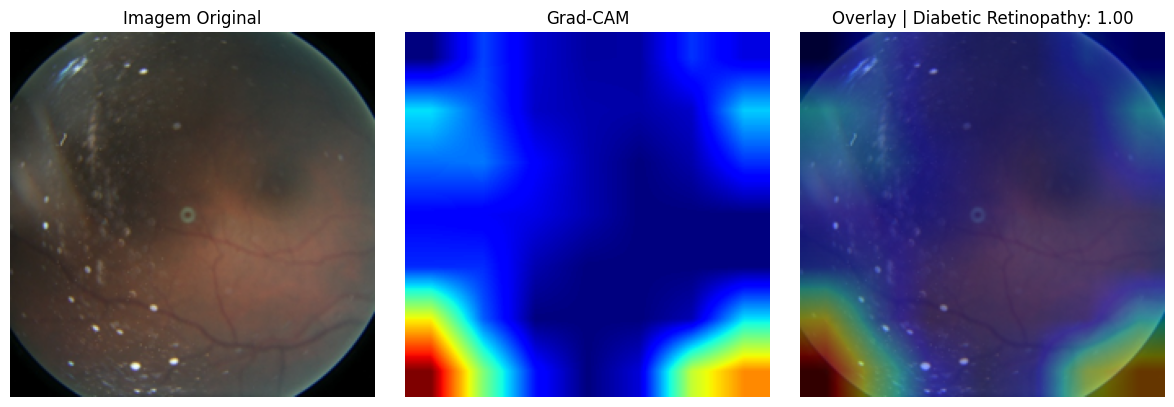

ResNet50 — Normal


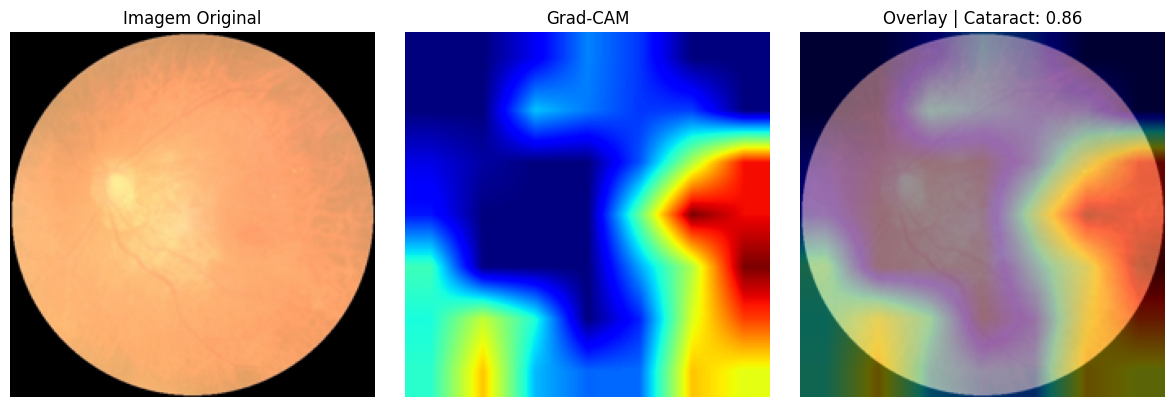

In [45]:
# índices de exemplo por classe no conjunto de teste

idx_cataract  = np.where(y_test == 0)[0][0]
idx_diabetic  = np.where(y_test == 1)[0][0]
idx_normal    = np.where(y_test == 2)[0][0]

# CNN Regularizado

for idx, cls in [(idx_cataract, "Cataract"), (idx_diabetic, "Diabetic"), (idx_normal, "Normal")]:
    print(f"Regularizado — {cls}")
    show_grad_cam(model_regularized, X_test[idx], class_names, "conv2d_2")

# EfficientNetB0 fine-tuned

for idx, cls in [(idx_cataract, "Cataract"), (idx_diabetic, "Diabetic"), (idx_normal, "Normal")]:
    print(f"EfficientNetB0 — {cls}")
    show_grad_cam(model_effnet, X_test_tl[idx], class_names, "top_conv", base_model=base_model)

# ResNet50 fine-tuned

for idx, cls in [(idx_cataract, "Cataract"), (idx_diabetic, "Diabetic"), (idx_normal, "Normal")]:
    print(f"ResNet50 — {cls}")
    show_grad_cam(model_resnet, X_test_tl[idx], class_names, "conv5_block3_out", base_model=base_model_resnet)

## 6. Modelo Multimodal

Como extensão opcional, desenvolvemos um modelo multimodal capaz de integrar duas
modalidades de informação: as **imagens oftalmológicas** e os **relatórios clínicos**
associados a cada exame.

A motivação é avaliar se a informação textual acrescenta valor discriminativo face à
imagem isolada — particularmente nas classes patológicas onde a imagem pode ser
ambígua ou de baixa qualidade.

A arquitetura combina dois ramos independentes:
- **Ramo visual** — ResNet50 pré-treinada (congelada) como extractor de features,
  o *champion* dos modelos CNN testados;
- **Ramo textual** — embeddings gerados pelo **BERTimbau**
  (`neuralmind/bert-base-portuguese-cased`), um modelo BERT pré-treinado para
  português, seguindo a metodologia apresentada em aula.

As representações dos dois ramos são concatenadas e passadas por camadas densas
para a classificação final nas três classes (*Cataract*, *Diabetic Retinopathy*,
*Normal*).

O desempenho do modelo multimodal é comparado directamente com o ResNet50 fine-tuned,
permitindo quantificar o contributo do texto para a classificação.


In [46]:

# Carregar e alinhar os relatórios clínicos com as imagens

report_path = os.path.join(base_dir, "ocular", "ocular_reports.csv")
df_reports  = pd.read_csv(report_path)

# extrair só o nome do ficheiro para fazer o join
df_reports["filename"] = df_reports["image_path"].apply(lambda x: x.split("\\")[-1])

print("Shape:", df_reports.shape)
print("Reports em falta:", df_reports["report"].isna().sum())
df_reports.head()

Shape: (2570, 4)
Reports em falta: 0


,image_path,label,report,filename
0,dataset\cataract\0_left.jpg,cataract,A imagem apresenta achados pouco específicos. ...,0_left.jpg
1,dataset\cataract\103_left.jpg,cataract,A visualização do fundo ocular encontra-se par...,103_left.jpg
2,dataset\cataract\1062_right.jpg,cataract,Recomenda-se correlação com avaliação clínica....,1062_right.jpg
3,dataset\cataract\1083_left.jpg,cataract,A interpretação deve considerar a qualidade da...,1083_left.jpg
4,dataset\cataract\1084_right.jpg,cataract,A vascularização apresenta aspeto regular. Não...,1084_right.jpg


In [47]:
# exemplo de um relatório

print(df_reports["report"].iloc[0])

A imagem apresenta achados pouco específicos. Observa-se redução da transparência das estruturas oculares. Sugere-se avaliação oftalmológica se clinicamente indicado.


In [48]:
# verificação de relatório únicos

print("Reports únicos:", df_reports["report"].nunique())

Reports únicos: 1477


In [49]:
# verificar se há imagens sem report

print("Reports em falta:", df_reports["report"].isna().sum())

# distribuição de reports por classe

print(df_reports["label"].value_counts())

Reports em falta: 0
label
diabetic_retinopathy    1098
normal                  1074
cataract                 398
Name: count, dtype: int64


In [50]:
#  Verificação de palavras mais frequentes por classe

for classe in df_reports["label"].unique():
    texto = " ".join(df_reports[df_reports["label"] == classe]["report"])
    palavras = re.findall(r'\b\w+\b', texto.lower())
    mais_comuns = Counter(palavras).most_common(10)
    print(f"\n--- {classe} ---")
    print(mais_comuns)


--- cataract ---
[('a', 768), ('se', 685), ('do', 485), ('imagem', 397), ('com', 384), ('cristalino', 306), ('da', 268), ('avaliação', 207), ('apresenta', 205), ('alterações', 202)]

--- diabetic_retinopathy ---
[('a', 1736), ('se', 1391), ('imagem', 723), ('com', 632), ('avaliação', 550), ('alterações', 539), ('existem', 538), ('discretas', 534), ('apresenta', 534), ('achados', 526)]

--- normal ---
[('a', 1689), ('se', 1387), ('imagem', 1139), ('com', 1079), ('alterações', 921), ('aspeto', 857), ('é', 720), ('não', 697), ('avaliação', 567), ('apresenta', 530)]


In [51]:
!pip install nltk

In [52]:
# definir stop words a retirar
nltk.download("stopwords")
stop_pt = set(stopwords.words("portuguese"))

# palavras mais frequentes por classe SEM stopwords
for classe in df_reports["label"].unique():
    texto   = " ".join(df_reports[df_reports["label"] == classe]["report"])
    palavras = re.findall(r'\b\w+\b', texto.lower())
    filtradas = [p for p in palavras if p not in stop_pt]
    mais_comuns = Counter(filtradas).most_common(10)
    print(f"\n--- {classe} ---")
    for palavra, count in mais_comuns:
        print(f"   {palavra}: {count}")


--- cataract ---
   imagem: 397
   cristalino: 306
   avaliação: 207
   apresenta: 205
   alterações: 202
   parcialmente: 196
   fundo: 186
   ocular: 186
   achados: 185
   visualização: 179

--- diabetic_retinopathy ---
   imagem: 723
   avaliação: 550
   alterações: 539
   existem: 538
   discretas: 534
   apresenta: 534
   achados: 526
   observam: 512
   fundo: 504
   ocular: 504

--- normal ---
   imagem: 1139
   alterações: 921
   aspeto: 857
   avaliação: 567
   apresenta: 530
   observam: 522
   compatível: 486
   ausência: 459
   evidentes: 459
   estruturas: 454


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [53]:
# Carregamento do BERTimbau — modelo BERT pré-treinado para português (neuralmind)
# Utilizado para gerar embeddings semânticos dos relatórios clínicos
# O modelo é movido para GPU se disponível, e colocado em modo de inferência (eval)

MODEL_NAME = "neuralmind/bert-base-portuguese-cased"

tokenizer  = AutoTokenizer.from_pretrained(MODEL_NAME)
model_bert = AutoModel.from_pretrained(MODEL_NAME)

device     = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_bert = model_bert.to(device)
model_bert.eval()

print("Device:", device)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/647 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/43.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/210k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/438M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Device: cuda


In [54]:
def mean_pooling(last_hidden_state, attention_mask):
    """
    Calcula a média dos embeddings dos tokens reais, ignorando padding.
    Mais robusto que usar apenas o token [CLS] para representar o texto completo.
    """
    mask            = attention_mask.unsqueeze(-1).expand(last_hidden_state.size()).float()
    soma_embeddings = torch.sum(last_hidden_state * mask, dim=1)  # soma apenas tokens reais
    soma_mask       = torch.clamp(mask.sum(dim=1), min=1e-9)      # evitar divisão por zero
    return soma_embeddings / soma_mask

def embeddings_relatorios(textos, batch_size=16, max_length=128):
    """
    Transforma uma lista de relatórios em embeddings BERTimbau via mean pooling.
    Processa em batches para eficiência. Devolve matriz (n_textos, 768).
    """
    embeddings = []
    for i in range(0, len(textos), batch_size):
        batch  = list(textos[i:i + batch_size])
        inputs = tokenizer(batch, return_tensors="pt",
                           truncation=True, padding=True, max_length=max_length)
        inputs = {k: v.to(device) for k, v in inputs.items()}  # mover para GPU se disponível
        with torch.no_grad():
            outputs = model_bert(**inputs)
        batch_embeddings = mean_pooling(outputs.last_hidden_state, inputs["attention_mask"])
        embeddings.append(batch_embeddings.cpu().numpy())
    return np.vstack(embeddings)  # (n_textos, 768)

In [55]:
# reconstruir a ordem de carregamento das imagens
# 1. extrair filename
df_reports["filename"] = df_reports["image_path"].apply(lambda x: x.split("\\")[-1])

# 2. gerar embeddings
print("A gerar embeddings...")
X_bert = embeddings_relatorios(df_reports["report"], batch_size=16, max_length=128)
print("Shape:", X_bert.shape)

# 3. alinhar com a ordem de carregamento
# Reuse the captured load order instead of re-listing the folders, so the
# reports line up with X_original by construction.
nomes_ordenados_reports = list(nomes_ficheiros)

df_reports_aligned = pd.DataFrame({"filename": nomes_ordenados_reports})
df_reports_aligned = df_reports_aligned.merge(df_reports, on="filename", how="left")

# A silent left-join miss would pair an image with an empty report.
assert len(df_reports_aligned) == len(X_original), \
    f"reports alinhados ({len(df_reports_aligned)}) != X_original ({len(X_original)})"
assert df_reports_aligned["report"].isna().sum() == 0, \
    f"{df_reports_aligned['report'].isna().sum()} imagens sem relatório após o merge!"

print("Shape:", df_reports_aligned.shape)
print("Reports em falta após merge:", df_reports_aligned["report"].isna().sum())

X_bert_ordered = np.array([
    X_bert[df_reports[df_reports["filename"] == fn].index[0]]
    for fn in df_reports_aligned["filename"]
])
print("Shape embeddings alinhados:", X_bert_ordered.shape)

A gerar embeddings...


model.safetensors:   0%|          | 0.00/438M [00:00<?, ?B/s]

Shape: (2570, 768)
Shape: (2570, 4)
Reports em falta após merge: 0
Shape embeddings alinhados: (2570, 768)


In [56]:
# aplicar os mesmos splits do X_original aos embeddings BERT
X_bert_trainval = X_bert_ordered[trainval_idx]
X_bert_test     = X_bert_ordered[test_idx]

X_bert_train = X_bert_trainval[train_idx]
X_bert_val   = X_bert_trainval[val_idx]

print("BERT treino:", X_bert_train.shape)
print("BERT val:   ", X_bert_val.shape)
print("BERT teste: ", X_bert_test.shape)

BERT treino: (1541, 768)
BERT val:    (522, 768)
BERT teste:  (507, 768)


In [57]:
# Modelo Multimodal
# Ramo da imagem — ResNet50 congelada como extractor de features
base_model_mm = ResNet50(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)
base_model_mm.trainable = False

image_input = tf.keras.Input(shape=(224, 224, 3), name="image_input")
x_img = tf.keras.layers.Lambda(
    lambda img: tf.keras.applications.resnet50.preprocess_input(img)
)(image_input)
x_img = base_model_mm(x_img, training=False)
x_img = tf.keras.layers.GlobalAveragePooling2D()(x_img)
x_img = tf.keras.layers.Dense(128, activation="relu")(x_img)
x_img = tf.keras.layers.Dropout(0.3)(x_img)

# Ramo do texto — embeddings BERTimbau (768d) → Dense
text_input = tf.keras.Input(shape=(768,), name="text_input")
x_text = tf.keras.layers.Dense(128, activation="relu")(text_input)
x_text = tf.keras.layers.Dense(32, activation="relu")(x_text)
x_text = tf.keras.layers.Dropout(0.3)(x_text)

# Fusão — concatenar imagem + texto
x = tf.keras.layers.Concatenate()([x_img, x_text])
x = tf.keras.layers.Dense(128, activation="relu")(x)
x = tf.keras.layers.Dropout(0.1)(x)
output = tf.keras.layers.Dense(3, activation="softmax", name="class_output")(x)

model_multimodal = tf.keras.Model(
    inputs={"image_input": image_input, "text_input": text_input},
    outputs=output
)

model_multimodal.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_multimodal.summary()

Model: "functional_10"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_input         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda_1 (Lambda)   │ (None, 224, 224,  │          0 │ image_input[0][0] │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50            │ (None, 7, 7,      │ 23,587,712 │ lambda_1[0][0]    │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_input          │ (None, 768)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2048)      │          0 │ resnet50[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 128)       │     98,432 │ text_input[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 128)       │    262,272 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 32)        │      4,128 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128)       │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 32)        │          0 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 160)       │          0 │ dropout_1[0][0],  │
│ (Concatenate)       │                   │            │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 128)       │     20,608 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 128)       │          0 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ class_output        │ (None, 3)         │        387 │ dropout_3[0][0]   │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 23,973,539 (91.45 MB)

 Trainable params: 385,827 (1.47 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [58]:
es = EarlyStopping(monitor="val_loss",
                   patience=5,
                   restore_best_weights=True
                   )

history_multimodal = model_multimodal.fit(
    {
        "image_input": X_train_tl,
        "text_input":  X_bert_train
    },
    y_train_tl,
    validation_data=(
        {
            "image_input": X_val_tl,
            "text_input":  X_bert_val
        },
        y_val_tl
    ),
    epochs=20,
    batch_size=32,
    class_weight=class_weight,
    callbacks=[es],
    verbose=2
)

Epoch 1/20
49/49 - 15s - 305ms/step - accuracy: 0.8300 - loss: 0.3855 - val_accuracy: 0.9732 - val_loss: 0.0843
Epoch 2/20
49/49 - 4s - 89ms/step - accuracy: 0.9611 - loss: 0.1296 - val_accuracy: 0.9751 - val_loss: 0.0644
Epoch 3/20
49/49 - 4s - 89ms/step - accuracy: 0.9676 - loss: 0.1016 - val_accuracy: 0.9885 - val_loss: 0.0401
Epoch 4/20
49/49 - 4s - 89ms/step - accuracy: 0.9773 - loss: 0.0620 - val_accuracy: 0.9923 - val_loss: 0.0376
Epoch 5/20
49/49 - 4s - 89ms/step - accuracy: 0.9747 - loss: 0.0784 - val_accuracy: 0.9904 - val_loss: 0.0342
Epoch 6/20
49/49 - 4s - 86ms/step - accuracy: 0.9799 - loss: 0.0553 - val_accuracy: 0.9904 - val_loss: 0.0407
Epoch 7/20
49/49 - 4s - 89ms/step - accuracy: 0.9805 - loss: 0.0487 - val_accuracy: 0.9943 - val_loss: 0.0258
Epoch 8/20
49/49 - 4s - 89ms/step - accuracy: 0.9857 - loss: 0.0355 - val_accuracy: 0.9904 - val_loss: 0.0238
Epoch 9/20
49/49 - 4s - 89ms/step - accuracy: 0.9877 - loss: 0.0343 - val_accuracy: 0.9981 - val_loss: 0.0146
Epoch 10

### Comparação com ResNet50

Última train accuracy: 0.994808554649353
Última val accuracy:   0.9942528605461121
Melhor train accuracy: 0.994808554649353
Melhor val accuracy:   0.998084306716919


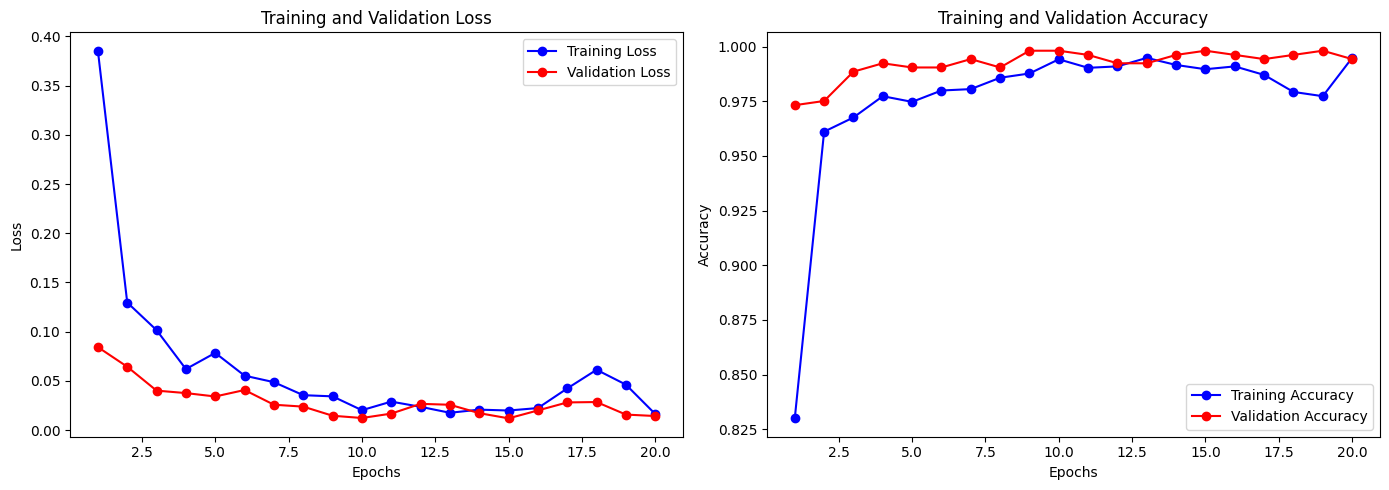

In [59]:
plot_training_history(history_multimodal)

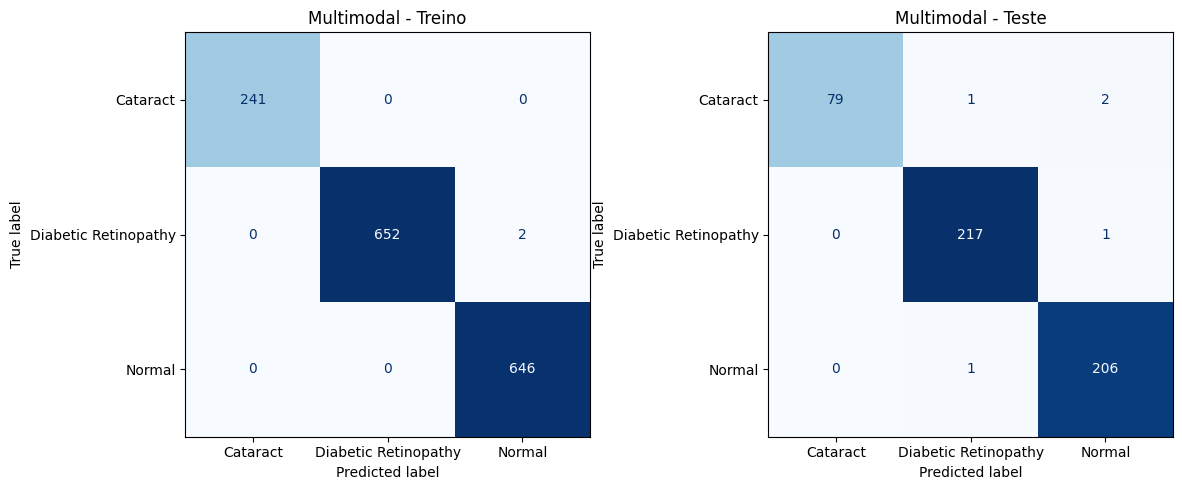

=== TREINO ===
                      precision    recall  f1-score   support

            Cataract       1.00      1.00      1.00       241
Diabetic Retinopathy       1.00      1.00      1.00       654
              Normal       1.00      1.00      1.00       646

            accuracy                           1.00      1541
           macro avg       1.00      1.00      1.00      1541
        weighted avg       1.00      1.00      1.00      1541

=== TESTE ===
                      precision    recall  f1-score   support

            Cataract       1.00      0.96      0.98        82
Diabetic Retinopathy       0.99      1.00      0.99       218
              Normal       0.99      1.00      0.99       207

            accuracy                           0.99       507
           macro avg       0.99      0.98      0.99       507
        weighted avg       0.99      0.99      0.99       507



In [60]:
# Treino
y_pred_multi_train = np.argmax(model_multimodal.predict(
    {"image_input": X_train_tl, "text_input": X_bert_train}, verbose=0
), axis=1)

# Teste
y_pred_multi_test = np.argmax(model_multimodal.predict(
    {"image_input": X_test_tl, "text_input": X_bert_test}, verbose=0
), axis=1)

# Matrizes de confusão
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay(confusion_matrix(y_train_tl, y_pred_multi_train),
                       display_labels=class_names).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Multimodal - Treino")

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_multi_test),
                       display_labels=class_names).plot(ax=axes[1], cmap="Blues", colorbar=False)
axes[1].set_title("Multimodal - Teste")
plt.tight_layout()
plt.show()

print("=== TREINO ===")
print(classification_report(y_train_tl, y_pred_multi_train, target_names=class_names))
print("=== TESTE ===")
print(classification_report(y_test, y_pred_multi_test, target_names=class_names))